<a href="https://colab.research.google.com/github/willismax/MediaSystem-Python-Course/blob/main/course-115-v2%20/colab/W08_0_%E5%85%88%E4%BF%AE_AI%E6%A8%A1%E5%9E%8B%E6%80%8E%E9%BA%BC%E5%AD%B8%E6%80%8E%E9%BA%BC%E7%94%A8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# W08-0｜先修：AI 模型怎麼學、怎麼用｜實作版
> **核心問題**：W08 的 LoRA 說「凍結原本的權重 W，只學一個更新量 ΔW」。權重是什麼？為什麼權重可以「學」？凍結之後，模型還能做什麼？
> **教學設計理念**：本 Notebook 依據「**問題 → 原理 → 實驗 → 驗證 → 反思**」五步學習法設計，落實 **CGRF 提示工程框架** 與 **三道防線驗證法**（閱讀理解、預測執行、邊界測試）。

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com)

---
### 📌 本章學習目標
1. 用 NumPy 寫出一個神經元，親手算出講義「小藍」範例的 $z = 1.64$、分數約 0.84。
2. 把一層神經網路寫成 `W @ x + b`，看懂權重 W 就是一張數字表。
3. 親手跑梯度下降，看 Loss 怎麼下降，以及 Learning Rate 太大、太小時會怎樣。
4. 用訓練 Loss 與驗證 Loss 判斷模型是學到規律，還是只記住了訓練資料（過擬合）。
5. 比較從零訓練、完整微調、只訓練最後一層，並確認推論時權重不會改變。
6. 用玩具語言模型體驗「一個 Token 接一個 Token」的生成，看幻覺怎麼出現。
7. 做一個不需要 API Key 的玩具 RAG，看檢索怎麼在不改權重的情況下改變答案。
8. 依「改不改權重」比較 Prompt、RAG／Reference、Fine-tuning／LoRA 與從頭預訓練。

### 這份 Notebook 怎麼用
每個 Lab 都照同一個節奏走：

| 步驟 | 你要做的事 |
| --- | --- |
| 問題 | 讀一段情境，知道這個 Lab 要回答什麼 |
| 預測 | **先**在「✍️ 我的預測」格寫下答案，再執行程式 |
| 實驗 | 執行程式；看到「🔧 動手改」時，一次只改一個變因 |
| 觀察 | 把看到的數字或圖片寫進「👀 觀察」格 |
| 反思 | 回答 1～2 題，對照講義章節 |

這一章只要求直覺，不推導微積分。程式都已經寫好，你的工作是預測、執行、改一個數字、觀察結果。預測寫錯沒有關係，評分看的是「預測 → 結果 → 解釋」有沒有接起來。

| Lab | 主題 | 對應講義 | 預估時間 |
| --- | --- | --- | --- |
| 1 | 模型就是函數：一個神經元 | 0.1–0.2 | 10 分鐘 |
| 2 | 一層就是矩陣運算 | 0.3 | 10 分鐘 |
| 3 | 訓練迴圈：Loss、梯度下降、Learning Rate | 0.4 | 15 分鐘 |
| 4 | 過擬合與驗證資料 | 0.4 | 10 分鐘 |
| 5 | 預訓練、微調與推論 | 0.5–0.6 | 15 分鐘 |
| 6 | 玩具語言模型：下一個 Token | 0.7 | 15 分鐘 |
| 7 | 玩具 RAG：先查資料，再回答 | 0.8 | 15 分鐘 |
| 8 | 四種方式比較＋自我檢測 | 0.9–0.11 | 10 分鐘 |

全部只用 CPU，Colab 內建的套件就夠（NumPy、Matplotlib、pandas、scikit-learn、PyTorch、ipywidgets），不需要 GPU，也不需要任何 API Key。每個 Lab 的程式大約半分鐘內跑完（第一次載入 PyTorch 會多等幾秒）。亂數種子全部固定，重跑會得到一樣的數字。

執行順序：先執行下方「環境設定」，之後每個 Lab 都可以單獨執行。

## 0. 環境設定（必做，只要執行一次）
下面這格會載入套件、固定亂數種子，並設定 Matplotlib 中文字型。字型下載失敗也不會中斷，只是圖上的中文可能顯示成方框。

In [ ]:
# @title 環境設定：套件、亂數種子、中文字型
import os, sys, time, math, json, copy, warnings, urllib.request
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
import pandas as pd
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=UserWarning)
IN_COLAB = "google.colab" in sys.modules
SEED = 42
np.random.seed(SEED)

FONT_PATH = "TaipeiSansTCBeta-Regular.ttf"
FONT_URL = "https://drive.google.com/uc?id=1eGAsTN1HBpJAkeVM57_C7ccp7hbgSz3_&export=download"
FALLBACK_FONTS = ["Taipei Sans TC Beta", "Noto Sans CJK TC", "Noto Sans TC", "Noto Sans CJK JP",
                  "Microsoft JhengHei", "PingFang TC", "Heiti TC", "WenQuanYi Zen Hei"]


def setup_chinese_font():
    """依序嘗試：課程字型檔 → 系統已安裝的中文字型。全部失敗時只印提醒，不中斷。"""
    if not (os.path.exists(FONT_PATH) and os.path.getsize(FONT_PATH) > 100_000):
        try:
            urllib.request.urlretrieve(FONT_URL, FONT_PATH)
        except Exception as e:
            print("課程字型下載失敗（", type(e).__name__, "），改找系統字型。")
    # Google Drive 有時回傳 HTML 頁面而不是字型檔，用檔案大小過濾
    if os.path.exists(FONT_PATH) and os.path.getsize(FONT_PATH) < 100_000:
        os.remove(FONT_PATH)
    if os.path.exists(FONT_PATH):
        try:
            font_manager.fontManager.addfont(FONT_PATH)
        except Exception as e:
            print("字型檔無法載入：", e)
    installed = {f.name for f in font_manager.fontManager.ttflist}
    for name in FALLBACK_FONTS:
        if name in installed:
            plt.rcParams["font.family"] = "sans-serif"
            plt.rcParams["font.sans-serif"] = [name, "DejaVu Sans"]
            plt.rcParams["axes.unicode_minus"] = False
            return name
    print("⚠️ 找不到中文字型，圖表中文可能顯示為方框，但不影響實驗結果。")
    return None


FONT_NAME = setup_chinese_font()

# 本章共用的小工具
FEATURES = ["短黑髮", "圓眼鏡", "深藍帽T"]          # 講義 0.2 的三個特徵


def sigmoid(z):
    """把任何實數壓到 0～1。先 clip，避免 Learning Rate 太大時 exp 溢位。"""
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))


try:
    import ipywidgets as widgets
    HAS_WIDGETS = True
except ImportError:
    HAS_WIDGETS = False

print("中文字型：", FONT_NAME)
print("Python", sys.version.split()[0], "｜NumPy", np.__version__, "｜Matplotlib", matplotlib.__version__)
print("在 Colab 執行：", IN_COLAB, "｜ipywidgets：", "可用" if HAS_WIDGETS else "未安裝，互動格會改用固定數值")

中文字型： Taipei Sans TC Beta
Python 3.13.16 ｜NumPy 2.1.3 ｜Matplotlib 3.10.0
在 Colab 執行： True ｜ipywidgets： 可用


---
## Lab 1｜模型就是函數：一個神經元（講義 0.1–0.2）

### 問題
我們想讓電腦認出原創角色「小藍」：短黑髮、圓眼鏡、深藍帽T。假設已經有人把一張圖轉成三個 0～1 的數字，代表三個特徵各有多明顯。一個神經元要怎麼把這三個數字變成「像不像小藍」的分數？

### 原理
模型就是一個函數：輸入 → 模型 → 輸出。一個神經元做三件事：

1. 每個輸入乘上一個 **權重（Weight）**。
2. 加起來，再加上 **偏差值（Bias）**：$z = w_1x_1 + w_2x_2 + w_3x_3 + b$
3. 經過 **激活函數（Activation Function）** Sigmoid，把 $z$ 壓到 0～1：$\sigma(z) = \dfrac{1}{1+e^{-z}}$

講義 0.2 的例子：$w_1=1.2,\ w_2=2.0,\ w_3=0.8,\ b=-2.0$；一張圖的特徵是短黑髮 0.9、圓眼鏡 1.0、深藍帽T 0.7。

### ✍️ 我的預測（先寫，再執行）
1. 先用紙筆算：這張圖的 $z$ 是多少？
2. $z$ 經過 Sigmoid 之後，大約是 0.5、0.84 還是 0.99？
3. 一張圖只有圓眼鏡 $(0, 1, 0)$，另一張只有深藍帽T $(0, 0, 1)$，哪一張分數比較高？

> 我的預測：
> 1.
> 2.
> 3.

In [ ]:
# @title Lab 1-1：一個神經元＝加權總和＋偏差＋Sigmoid
def neuron(x, w, b):
    """回傳 (z, 分數)。x、w 是長度相同的一維陣列。"""
    z = float(np.dot(w, x) + b)
    return z, float(sigmoid(z))


w = np.array([1.2, 2.0, 0.8])    # 短黑髮、圓眼鏡、深藍帽T 的權重
b = -2.0                         # 偏差值
x = np.array([0.9, 1.0, 0.7])    # 一張圖的三個特徵

z, score = neuron(x, w, b)
for name, wi, xi in zip(FEATURES, w, x):
    print(f"{name}：權重 {wi:.1f} × 特徵 {xi:.1f} = {wi * xi:.2f}")
print(f"加上偏差 b = {b}")
print(f"z = {z:.2f}")
print(f"Sigmoid(z) = {score:.4f} → 約 {score:.0%} 像小藍")
assert abs(z - 1.64) < 1e-9 and round(score, 2) == 0.84   # 與講義 0.2 一致

短黑髮：權重 1.2 × 特徵 0.9 = 1.08
圓眼鏡：權重 2.0 × 特徵 1.0 = 2.00
深藍帽T：權重 0.8 × 特徵 0.7 = 0.56
加上偏差 b = -2.0
z = 1.64
Sigmoid(z) = 0.8375 → 約 84% 像小藍


,圖,短黑髮,圓眼鏡,深藍帽T,z,像小藍的分數
0,講義範例,0.9,1.0,0.7,1.64,0.838
1,只有圓眼鏡,0.0,1.0,0.0,0.00,0.500
2,只有深藍帽T,0.0,0.0,1.0,-1.20,0.231
3,短黑髮＋帽T，沒眼鏡,0.9,0.0,0.9,-0.20,0.450
4,三個特徵都沒有,0.0,0.0,0.0,-2.00,0.119
5,三個特徵都滿分,1.0,1.0,1.0,2.00,0.881


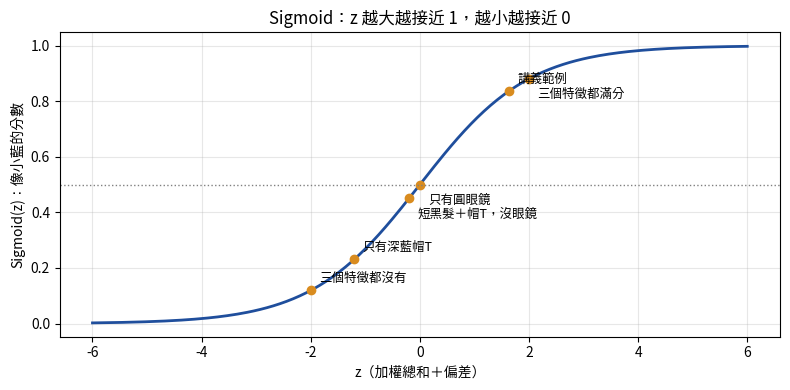

In [ ]:
# @title Lab 1-2：同一組權重，換不同的圖
images = {
    "講義範例": [0.9, 1.0, 0.7],
    "只有圓眼鏡": [0.0, 1.0, 0.0],
    "只有深藍帽T": [0.0, 0.0, 1.0],
    "短黑髮＋帽T，沒眼鏡": [0.9, 0.0, 0.9],
    "三個特徵都沒有": [0.0, 0.0, 0.0],
    "三個特徵都滿分": [1.0, 1.0, 1.0],
}
rows = []
for name, feats in images.items():
    z_i, s_i = neuron(np.array(feats), w, b)
    rows.append({"圖": name, **dict(zip(FEATURES, feats)), "z": round(z_i, 2), "像小藍的分數": round(s_i, 3)})
display(pd.DataFrame(rows))

# Sigmoid 曲線：每張圖落在哪裡
zs = np.linspace(-6, 6, 200)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(zs, sigmoid(zs), lw=2, color="#1f4e9c")
for i, (name, feats) in enumerate(images.items()):
    z_i, s_i = neuron(np.array(feats), w, b)
    ax.plot(z_i, s_i, "o", color="#d98c1f")
    ax.annotate(name, (z_i, s_i), textcoords="offset points", xytext=(6, -14 if i % 2 else 6), fontsize=9)
ax.axhline(0.5, color="gray", ls=":", lw=1)
ax.set_xlabel("z（加權總和＋偏差）"); ax.set_ylabel("Sigmoid(z)：像小藍的分數")
ax.set_title("Sigmoid：z 越大越接近 1，越小越接近 0"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

### 🔧 動手改 1：只改一個權重
把 `my_w` 裡的 w2（圓眼鏡）從 2.0 改成 0.5，其他不動。執行前先預測：講義範例那張圖的分數會變高還是變低？大概變多少？

In [ ]:
# @title 🔧 動手改：一次只改一個數字
my_w = np.array([1.2, 0.5, 0.8])   # TODO: 只改其中一個權重
my_b = -2.0                        # TODO: 或只改 b

z_old, s_old = neuron(x, w, b)
z_new, s_new = neuron(x, my_w, my_b)
print(f"原本：z = {z_old:.2f}，分數 = {s_old:.3f}")
print(f"修改：z = {z_new:.2f}，分數 = {s_new:.3f}（變化 {s_new - s_old:+.3f}）")

原本：z = 1.64，分數 = 0.838
修改：z = 0.14，分數 = 0.535（變化 -0.303）


### 🔧 動手改 2：拉動滑桿
拉動 `w1`～`w3` 與 `b`，看長條圖上每一項的貢獻怎麼變。試著找出：
- 讓「講義範例」分數低於 0.5 的最小改動。
- 一組權重，讓這個神經元變成「只看深藍帽T」。

滑桿無法顯示時（例如沒有安裝 ipywidgets），直接改 `show_neuron(...)` 的參數。

In [ ]:
# @title 🔧 互動滑桿：拉權重，看每個特徵貢獻多少
def show_neuron(w1=1.2, w2=2.0, w3=0.8, b=-2.0, x1=0.9, x2=1.0, x3=0.7):
    ww, xx = np.array([w1, w2, w3]), np.array([x1, x2, x3])
    z_, s_ = neuron(xx, ww, b)
    vals = list(ww * xx) + [b]
    labels = [f"{n}\n{wi:.1f}×{xi:.1f}" for n, wi, xi in zip(FEATURES, ww, xx)] + ["偏差 b"]
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [3, 2]})
    axes[0].bar(labels, vals, color=["#1f4e9c" if v >= 0 else "#c44e52" for v in vals])
    axes[0].axhline(0, color="k", lw=.8); axes[0].set_title(f"各項貢獻，加總 z = {z_:.2f}")
    axes[1].barh(["像小藍"], [s_], color="#55a868"); axes[1].set_xlim(0, 1)
    axes[1].axvline(0.5, color="gray", ls=":"); axes[1].set_title(f"Sigmoid(z) = {s_:.3f}")
    plt.tight_layout(); plt.show()


if HAS_WIDGETS:
    def _sl(v, lo, hi):
        return widgets.FloatSlider(value=v, min=lo, max=hi, step=0.1, continuous_update=False)
    widgets.interact(show_neuron, w1=_sl(1.2, -3, 3), w2=_sl(2.0, -3, 3), w3=_sl(0.8, -3, 3), b=_sl(-2.0, -4, 4),
                     x1=_sl(0.9, 0, 1), x2=_sl(1.0, 0, 1), x3=_sl(0.7, 0, 1))
else:
    show_neuron()   # TODO: 沒有滑桿時，直接改這裡，例如 show_neuron(w2=0.5)

interactive(children=(FloatSlider(value=1.2, continuous_update=False, description='w1', max=3.0, min=-3.0), Fl…

### 👀 觀察
- 講義範例的 z 與分數：
- 「只有圓眼鏡」和「只有深藍帽T」的分數各是多少：
- 把 w2 改成 0.5 之後，分數變成：
- 讓範例分數低於 0.5 的最小改動：

### 反思
1. w2 最大，代表這個神經元最看重哪個特徵？如果把 w2 改成負數，「戴圓眼鏡」對分數的影響會變成什麼？
2. 偏差 $b=-2.0$ 讓「三個特徵都沒有」的圖只有約 12%。如果 $b$ 改成 0，這張圖會變成多少？這樣合理嗎？

---
## Lab 2｜一層就是矩陣運算（講義 0.3）

### 問題
一個神經元只會看一件事。把很多個神經元並排，就是一層。一層有一百個神經元時，程式要寫一百次嗎？W08 說 LoRA 要「凍結 W」，那個 W 到底長什麼樣子？

### 原理
每個神經元有自己的一排權重。把這些排疊成一張表，就是 **權重矩陣 W**：每一列（row）是一個神經元，每一行（column）對應一個輸入特徵。整層的計算寫成

$$y = Wx + b$$

在 NumPy 裡就是 `W @ x + b`。講義 0.3 的 W：

| | 短黑髮 | 圓眼鏡 | 深藍帽T |
| --- | --- | --- | --- |
| 神經元 1 | 1.2 | 2.0 | 0.8 |
| 神經元 2 | −0.5 | 0.3 | 1.5 |

講義沒有給神經元 2 的偏差，這裡先設成 −0.5。

### ✍️ 我的預測
1. 用 `W @ x + b` 算出來的神經元 1，會和 Lab 1 一樣是 1.64 嗎？
2. 神經元 2 最看重哪個特徵？它對講義範例的 $z$ 大約是多少？
3. 一個 3 → 4 → 2 → 1 的小網路（每層都有偏差），總共有幾個參數？

> 我的預測：
> 1.
> 2.
> 3.

In [ ]:
# @title Lab 2-1：把權重排成一張表
W = np.array([[ 1.2, 2.0, 0.8],    # 神經元 1：最看重圓眼鏡
              [-0.5, 0.3, 1.5]])   # 神經元 2：最看重深藍帽T
b_vec = np.array([-2.0, -0.5])
x = np.array([0.9, 1.0, 0.7])      # 講義範例

display(pd.DataFrame(W, index=["神經元 1", "神經元 2"], columns=FEATURES))
print("W 的形狀：", W.shape, "→ 2 個神經元 × 3 個輸入特徵")

# 逐一計算 vs 一次矩陣運算
z_loop = []
for i in range(W.shape[0]):                 # 一個神經元一個神經元算
    z_loop.append(sum(W[i, j] * x[j] for j in range(W.shape[1])) + b_vec[i])
z_mat = W @ x + b_vec                       # 一行算完整層
print("逐一計算：", np.round(z_loop, 2))
print("W @ x + b：", np.round(z_mat, 2))
print("Sigmoid  ：", np.round(sigmoid(z_mat), 3))
assert np.allclose(z_loop, z_mat) and abs(z_mat[0] - 1.64) < 1e-9   # 神經元 1 就是 Lab 1 的神經元

,短黑髮,圓眼鏡,深藍帽T
神經元 1,1.2,2.0,0.8
神經元 2,-0.5,0.3,1.5


W 的形狀： (2, 3) → 2 個神經元 × 3 個輸入特徵
逐一計算： [1.64 0.4 ]
W @ x + b： [1.64 0.4 ]
Sigmoid  ： [0.838 0.599]


,神經元 1 分數,神經元 2 分數
講義範例,0.838,0.599
只有圓眼鏡,0.500,0.450
短黑髮＋帽T,0.450,0.599
幾乎只有帽T,0.336,0.733


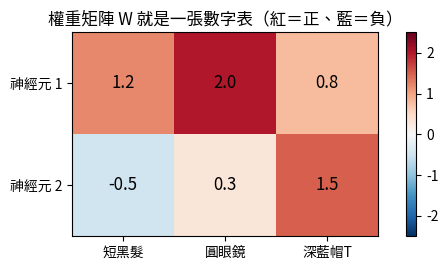

In [ ]:
# @title Lab 2-2：一次算很多張圖：X 的每一列是一張圖
X_imgs = np.array([[0.9, 1.0, 0.7],
                   [0.0, 1.0, 0.0],
                   [0.9, 0.0, 0.9],
                   [0.1, 0.2, 1.0]])
img_names = ["講義範例", "只有圓眼鏡", "短黑髮＋帽T", "幾乎只有帽T"]
Z = X_imgs @ W.T + b_vec        # (4 張圖 × 3 特徵) @ (3 × 2 個神經元) → 4 × 2
display(pd.DataFrame(np.round(sigmoid(Z), 3), index=img_names, columns=["神經元 1 分數", "神經元 2 分數"]))

fig, ax = plt.subplots(figsize=(6, 2.8))
im = ax.imshow(W, cmap="RdBu_r", vmin=-2.5, vmax=2.5)
ax.set_xticks(range(3)); ax.set_xticklabels(FEATURES)
ax.set_yticks(range(2)); ax.set_yticklabels(["神經元 1", "神經元 2"])
for (i, j), v in np.ndenumerate(W):
    ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=12)
fig.colorbar(im, ax=ax, fraction=0.046)
ax.set_title("權重矩陣 W 就是一張數字表（紅＝正、藍＝負）")
plt.tight_layout(); plt.show()

In [ ]:
# @title Lab 2-3：數參數：每一層 = 一張 W 表 + 一排 b
def count_params(layer_sizes):
    rows = []
    for i, (n_in, n_out) in enumerate(zip(layer_sizes[:-1], layer_sizes[1:]), start=1):
        rows.append({"層": f"第 {i} 層", "W 形狀": f"{n_out} × {n_in}", "W 參數": n_out * n_in,
                     "b 參數": n_out, "小計": n_out * n_in + n_out})
    df = pd.DataFrame(rows)
    return df, int(df["小計"].sum())


df_small, total_small = count_params([3, 4, 2, 1])
display(df_small)
print(f"小網路 3 → 4 → 2 → 1：共 {total_small:,} 個參數")
assert total_small == 29

_, total_big = count_params([4096] * 25)     # 24 層、每層 4096 × 4096 的玩具「大」網路
print(f"玩具大網路（24 層 4096 × 4096）：共 {total_big:,} 個參數，約 {total_big / 1e6:.0f} M")
print(f"其中一張 4096 × 4096 的 W 就有 {4096 * 4096:,} 個數字（W08 Lab 1 的參數帳用的就是這個大小）")
print(f"用 32-bit 浮點數存，玩具大網路約 {total_big * 4 / 1e9:.1f} GB")

,層,W 形狀,W 參數,b 參數,小計
0,第 1 層,4 × 3,12,4,16
1,第 2 層,2 × 4,8,2,10
2,第 3 層,1 × 2,2,1,3


小網路 3 → 4 → 2 → 1：共 29 個參數
玩具大網路（24 層 4096 × 4096）：共 402,751,488 個參數，約 403 M
其中一張 4096 × 4096 的 W 就有 16,777,216 個數字（W08 Lab 1 的參數帳用的就是這個大小）
用 32-bit 浮點數存，玩具大網路約 1.6 GB


### 和 W08 的連結
- W08 說 LoRA「凍結 W」，凍結的就是上面這種表：每一層的權重矩陣。凍結的意思是訓練時這張表的數字一個都不改。
- LoRA 另外學一個和 W 同樣形狀的更新量 $\Delta W$，但用兩張瘦長的表 $B$、$A$ 相乘來表示，所以要學的數字少很多。W08 Lab 1 會實際算這筆帳。
- 大型模型有幾億到上千億個參數，聽起來很抽象。換成這個 Lab 的說法：很多層、很大張的數字表，每個參數都只是表裡的一格。

### 🔧 動手改
在 W 加上第 3 個神經元「只看短黑髮」（例如權重 `[2.0, 0.0, 0.0]`、偏差 `-1.0`）。執行前先預測：新的 W 形狀是什麼？四張圖的輸出會變成幾 × 幾？

也可以改 `my_layers`，數數看你自己設計的網路有幾個參數。

In [ ]:
# @title 🔧 動手改：多一個神經元，W 多一列
new_row, new_b = [2.0, 0.0, 0.0], -1.0      # TODO: 改成你想要的神經元
W3 = np.vstack([W, new_row])
b3 = np.append(b_vec, new_b)
Z3 = sigmoid(X_imgs @ W3.T + b3)
print("新的 W 形狀：", W3.shape, "｜輸出形狀：", Z3.shape)
display(pd.DataFrame(np.round(Z3, 3), index=img_names, columns=["神經元 1", "神經元 2", "神經元 3"]))

my_layers = [3, 8, 8, 1]                     # TODO: 改成你自己的網路
df_my, total_my = count_params(my_layers)
print(f"{' → '.join(map(str, my_layers))}：共 {total_my:,} 個參數")

新的 W 形狀： (3, 3) ｜輸出形狀： (4, 3)


,神經元 1,神經元 2,神經元 3
講義範例,0.838,0.599,0.690
只有圓眼鏡,0.500,0.450,0.269
短黑髮＋帽T,0.450,0.599,0.690
幾乎只有帽T,0.336,0.733,0.310


3 → 8 → 8 → 1：共 113 個參數


### 👀 觀察
- 神經元 1、神經元 2 對講義範例的 $z$：
- 3 → 4 → 2 → 1 的參數量：
- 加上第 3 個神經元後，W 與輸出的形狀：

### 反思
1. 「只有圓眼鏡」的圖，在神經元 1 和神經元 2 的分數差很多。用 W 的數字解釋為什麼。
2. 用自己的話說明：W08 說 LoRA「凍結權重」的那個權重，在神經網路的哪裡？（講義檢核題 6）

---
## Lab 3｜訓練迴圈：Loss、梯度下降、Learning Rate（講義 0.4）

### 問題
Lab 1 的權重是我們直接給的。真正的模型有幾億個權重，不可能手動設定。給模型一批「是小藍／不是小藍」的範例，它要怎麼自己找到好的權重？

### 原理
訓練就是重複這個迴圈：

```text
預測 → 和正確答案比較，算出 Loss → 算出每個權重該往哪邊調 → 更新權重 → 回到預測
```

- **Loss**：這裡用二元交叉熵（Binary Cross-Entropy）。答案是 1 的圖，模型說 0.95 只扣一點，說 0.05 就扣很多。答錯又很有把握，扣得最重。
- **更新規則（用說的）**：先對每一筆資料算「誤差＝預測分數 − 正確答案」。
  - 誤差是正的（猜太高）：這筆資料上數值越大的特徵，權重就往下調越多。
  - 誤差是負的（猜太低）：反過來往上調。
  - 所有資料的建議取平均，再乘上 **Learning Rate**，就是這一步要走多遠。

寫成程式只有兩行：`w = w - lr * 平均(誤差 × x)`、`b = b - lr * 平均(誤差)`。這兩行背後的推導要用到微積分，這門課不需要，記得「往 Loss 變小的方向走一小步」就好。講義把這個做法叫做 **梯度下降（Gradient Descent）**。

為了把結果畫在平面上，這個 Lab 只用兩個特徵：圓眼鏡與深藍帽T。神經元還是同一種，只是少一個輸入。

### ✍️ 我的預測
1. Loss 在訓練的前幾步下降得快，還是最後幾步下降得快？
2. Learning Rate 0.05、5、200，哪一個最後的 Loss 最低？哪一個的曲線會上下跳？
3. 訓練完，圓眼鏡和深藍帽T 哪個權重比較大？

> 我的預測：
> 1.
> 2.
> 3.

資料筆數： 100 ｜小藍： 40 ｜不是小藍： 60


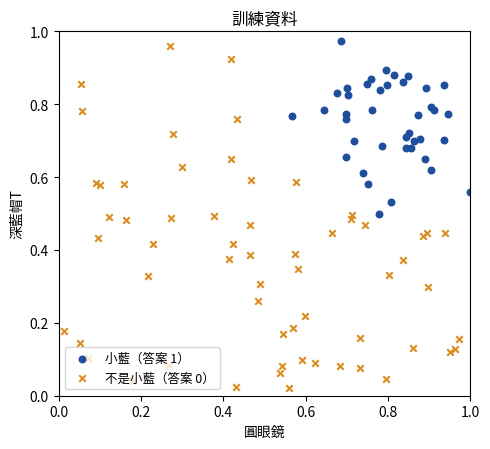

In [ ]:
# @title Lab 3-1：合成資料：「小藍」vs「不是小藍」
FEAT2 = ["圓眼鏡", "深藍帽T"]


def make_xiaolan_data(n_pos=40, n_neg=60, seed=SEED):
    rng = np.random.default_rng(seed)
    pos = np.column_stack([rng.normal(0.80, 0.12, n_pos), rng.normal(0.75, 0.15, n_pos)])          # 小藍
    neg_a = np.column_stack([rng.uniform(0.0, 0.6, n_neg // 2), rng.uniform(0.0, 1.0, n_neg // 2)])  # 沒戴圓眼鏡
    neg_b = np.column_stack([rng.uniform(0.4, 1.0, n_neg // 2), rng.uniform(0.0, 0.5, n_neg // 2)])  # 有眼鏡，沒穿深藍帽T
    X = np.clip(np.vstack([pos, neg_a, neg_b]), 0, 1)
    y = np.concatenate([np.ones(n_pos), np.zeros(n_neg)])
    return X, y


def scatter_data(ax, X, y):
    ax.scatter(*X[y == 1].T, c="#1f4e9c", marker="o", s=22, label="小藍（答案 1）")
    ax.scatter(*X[y == 0].T, c="#d98c1f", marker="x", s=22, label="不是小藍（答案 0）")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_xlabel(FEAT2[0]); ax.set_ylabel(FEAT2[1])


X3, y3 = make_xiaolan_data()
print("資料筆數：", len(y3), "｜小藍：", int(y3.sum()), "｜不是小藍：", int((1 - y3).sum()))
fig, ax = plt.subplots(figsize=(5, 4.6))
scatter_data(ax, X3, y3); ax.legend(loc="lower left", fontsize=9); ax.set_title("訓練資料")
plt.tight_layout(); plt.show()

訓練前 Loss = 0.711
訓練後 Loss = 0.129，訓練資料準確率 = 96%
學到的權重：圓眼鏡 9.53、深藍帽T 11.25、b = -13.50（0.02 秒）


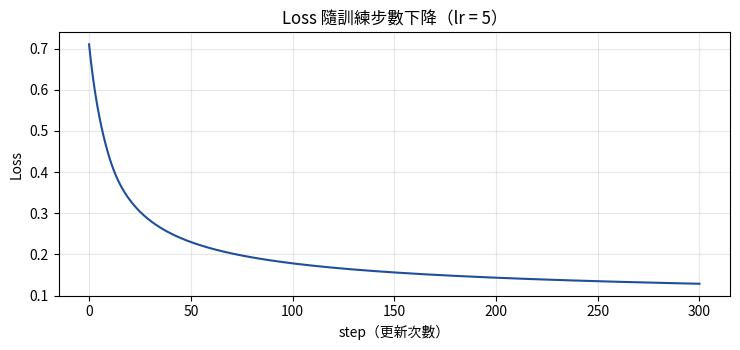

In [ ]:
# @title Lab 3-2：手寫梯度下降
def bce_loss(p, y, eps=1e-9):
    return float(-np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps)))


W_INIT, B_INIT = (-0.5, 0.3), 0.2            # 故意從一組「不好」的權重出發


def train_neuron(X, y, lr=5.0, steps=300):
    w = np.array(W_INIT, dtype=float); b = float(B_INIT)
    hist = {"loss": [], "w": [], "b": []}
    for step in range(steps + 1):
        p = sigmoid(X @ w + b)                   # 1. 預測
        hist["loss"].append(bce_loss(p, y))      # 2. 算 Loss
        hist["w"].append(w.copy()); hist["b"].append(b)
        if step == steps:
            break
        err = p - y                              # 3. 每筆資料猜高（+）或猜低（−）多少
        w = w - lr * (err[:, None] * X).mean(axis=0)   # 4. 往 Loss 變小的方向走一步
        b = b - lr * err.mean()
    return w, b, hist


t0 = time.perf_counter()
w_fit, b_fit, hist = train_neuron(X3, y3, lr=5.0, steps=300)
acc = np.mean((sigmoid(X3 @ w_fit + b_fit) > 0.5) == y3)
print(f"訓練前 Loss = {hist['loss'][0]:.3f}")
print(f"訓練後 Loss = {hist['loss'][-1]:.3f}，訓練資料準確率 = {acc:.0%}")
print(f"學到的權重：圓眼鏡 {w_fit[0]:.2f}、深藍帽T {w_fit[1]:.2f}、b = {b_fit:.2f}（{time.perf_counter() - t0:.2f} 秒）")

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(hist["loss"], color="#1f4e9c"); ax.set_xlabel("step（更新次數）"); ax.set_ylabel("Loss")
ax.set_title("Loss 隨訓練步數下降（lr = 5）"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

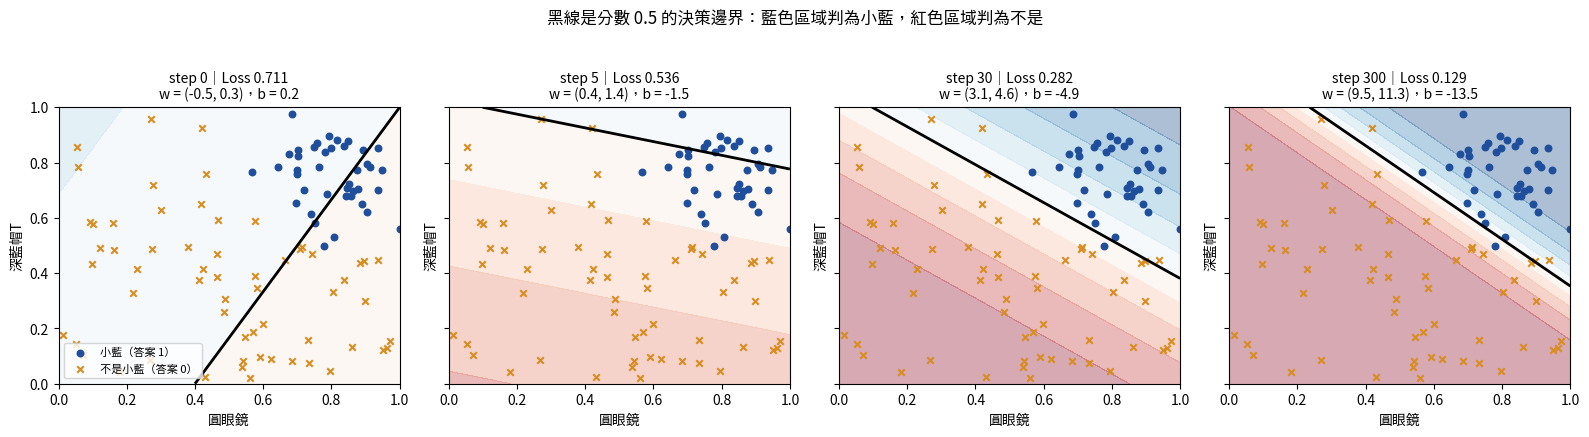

In [ ]:
# @title Lab 3-3：決策邊界怎麼移動：分數 = 0.5 的那條線
SNAP_STEPS = [0, 5, 30, 300]
gx, gy = np.meshgrid(np.linspace(0, 1, 120), np.linspace(0, 1, 120))
grid = np.column_stack([gx.ravel(), gy.ravel()])

fig, axes = plt.subplots(1, len(SNAP_STEPS), figsize=(16, 4.2), sharey=True)
for ax, s in zip(axes, SNAP_STEPS):
    ws, bs = hist["w"][s], hist["b"][s]
    prob = sigmoid(grid @ ws + bs).reshape(gx.shape)
    ax.contourf(gx, gy, prob, levels=np.linspace(0, 1, 11), cmap="RdBu", alpha=.35, vmin=0, vmax=1)
    ax.contour(gx, gy, prob, levels=[0.5], colors="k", linewidths=2)
    scatter_data(ax, X3, y3)
    ax.set_title(f"step {s}｜Loss {hist['loss'][s]:.3f}\nw = ({ws[0]:.1f}, {ws[1]:.1f})，b = {bs:.1f}", fontsize=10)
axes[0].legend(loc="lower left", fontsize=8)
plt.suptitle("黑線是分數 0.5 的決策邊界：藍色區域判為小藍，紅色區域判為不是", y=1.03)
plt.tight_layout(); plt.show()

### Learning Rate 實驗：太小、剛好、太大
同一份資料、同一組起始權重、同樣 300 步，只改 Learning Rate。

,設定,第 10 步 Loss,最後 Loss,Loss 不降反升的步數,準確率
0,太小 lr = 0.05,0.704,0.588,0,82%
1,剛好 lr = 5,0.435,0.129,0,96%
2,太大 lr = 200,7.156,0.595,148,95%


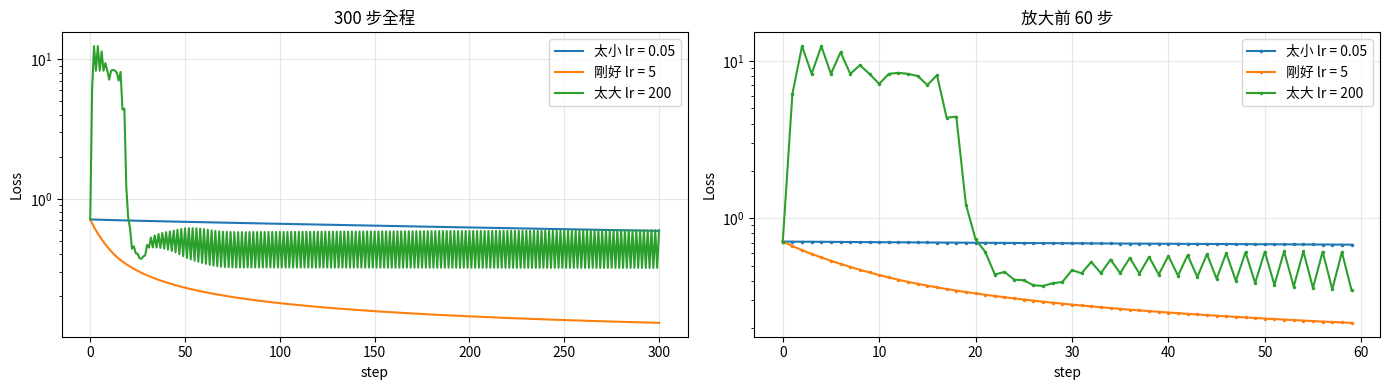

In [ ]:
# @title Lab 3-4：Learning Rate 實驗
LRS = {"太小 lr = 0.05": 0.05, "剛好 lr = 5": 5.0, "太大 lr = 200": 200.0}
lr_rows, lr_hists = [], {}
for label, lr in LRS.items():
    w_l, b_l, h_l = train_neuron(X3, y3, lr=lr, steps=300)
    lr_hists[label] = h_l["loss"]
    jumps = int(np.sum(np.diff(h_l["loss"]) > 1e-6))       # Loss 不降反升的次數
    lr_rows.append({"設定": label, "第 10 步 Loss": round(h_l["loss"][10], 3), "最後 Loss": round(h_l["loss"][-1], 3),
                    "Loss 不降反升的步數": jumps,
                    "準確率": f"{np.mean((sigmoid(X3 @ w_l + b_l) > 0.5) == y3):.0%}"})
display(pd.DataFrame(lr_rows))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for label, losses in lr_hists.items():
    axes[0].plot(losses, label=label)
    axes[1].plot(losses[:60], label=label, marker=".", ms=3)
axes[0].set_title("300 步全程"); axes[1].set_title("放大前 60 步")
for ax in axes:
    ax.set_xlabel("step"); ax.set_ylabel("Loss"); ax.set_yscale("log"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

### 🔧 動手改
改 `my_lr` 或 `my_steps`，一次只改一個。試試看：
- lr = 0.05 要走幾步，Loss 才追得上 lr = 5 走 300 步的結果？（提示：把 `my_steps` 加到 3000、30000 試試）
- 固定 300 步，lr 從 5 往上加（10、20、40、100），最後 Loss 最低的是哪一個？從哪裡開始出現上下跳、最後 Loss 反而變差？

lr = 0.05、3000 步：最後 Loss = 0.285（0.16 秒）
對照：lr = 5、300 步的最後 Loss = 0.129


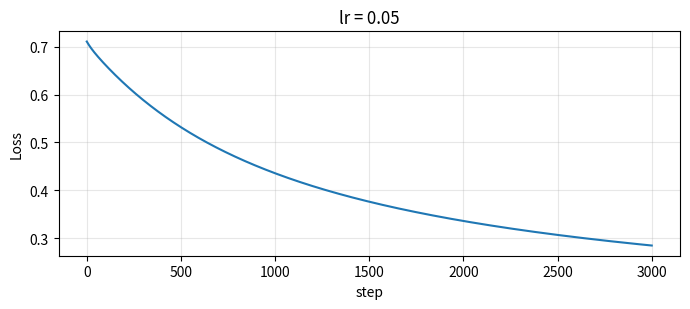

In [ ]:
# @title 🔧 動手改：一次只改一個
my_lr, my_steps = 0.05, 3000      # TODO

t0 = time.perf_counter()
w_m, b_m, h_m = train_neuron(X3, y3, lr=my_lr, steps=my_steps)
print(f"lr = {my_lr}、{my_steps} 步：最後 Loss = {h_m['loss'][-1]:.3f}（{time.perf_counter() - t0:.2f} 秒）")
print(f"對照：lr = 5、300 步的最後 Loss = {lr_hists['剛好 lr = 5'][-1]:.3f}")
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(h_m["loss"]); ax.set_xlabel("step"); ax.set_ylabel("Loss"); ax.grid(alpha=.3)
ax.set_title(f"lr = {my_lr}"); plt.tight_layout(); plt.show()

### 👀 觀察
- lr = 5 時，訓練前與訓練後的 Loss：
- 決策邊界在 step 0 和 step 300 的位置差在哪裡：
- 三種 Learning Rate 的最後 Loss，以及哪一條曲線上下跳：

### 反思
1. 講義用「矇著眼睛下山」比喻梯度下降。Learning Rate 太大時，對應到下山時的什麼情況？
2. 訓練完的兩個權重，哪個比較大？對照 Lab 3-1 的資料分布，說明模型為什麼會這樣學。

---
## Lab 4｜過擬合與驗證資料（講義 0.4）

### 問題
訓練 Loss 越來越低，就代表模型越來越好嗎？資料很少、模型很大的時候，會發生什麼事？

### 原理
把資料分成兩份：

- **訓練資料（Training Data）**：拿來調整權重。
- **驗證資料（Validation Data）**：模型從頭到尾沒看過，只拿來打分數。

```text
訓練 Loss 低、驗證 Loss 也低   → 學到規律
訓練 Loss 很低、驗證 Loss 很高 → 只記住了訓練資料（過擬合 Overfitting）
```

這個 Lab 用一個小型的多層神經網路（MLP），資料是兩群交錯成月牙形的點，位置帶有雜訊。Lab 3 是手寫梯度，從這個 Lab 開始改由 PyTorch 自動算梯度；迴圈還是同樣四步：預測、算 Loss、算梯度、更新權重。

### ✍️ 我的預測
1. 大模型（2 → 128 → 128 → 1）只用 20 筆資料訓練，訓練 Loss 會降到多低？驗證 Loss 呢？
2. 驗證 Loss 的最低點，會出現在訓練的開頭、中間還是最後？
3. 要改善過擬合，你會先試「增加資料」還是「縮小模型」？

> 我的預測：
> 1.
> 2.
> 3.

In [ ]:
# @title Lab 4-1：資料、模型與訓練函式
import torch
import torch.nn as nn
from sklearn.datasets import make_moons

torch.set_num_threads(min(4, os.cpu_count() or 1))


def make_split(n_train, n_val=400, noise=0.35, seed=0):
    X, y = make_moons(n_samples=n_train + n_val, noise=noise, random_state=seed)
    X = torch.tensor(X, dtype=torch.float32); y = torch.tensor(y, dtype=torch.float32)
    return X[:n_train], y[:n_train], X[n_train:], y[n_train:]


def make_mlp(hidden, seed=0):
    torch.manual_seed(seed)
    layers, n_in = [], 2
    for h in hidden:
        layers += [nn.Linear(n_in, h), nn.ReLU()]
        n_in = h
    layers.append(nn.Linear(n_in, 1))
    return nn.Sequential(*layers)


def n_params(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)


def fit(model, Xtr, ytr, Xva, yva, steps=1200, lr=1e-3):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()
    tr_hist, va_hist = [], []
    for _ in range(steps):
        opt.zero_grad()
        loss = loss_fn(model(Xtr).squeeze(1), ytr)    # 預測＋Loss
        loss.backward()                                # 算梯度（PyTorch 代勞）
        opt.step()                                     # 更新權重
        with torch.no_grad():
            va = loss_fn(model(Xva).squeeze(1), yva).item()
        tr_hist.append(loss.item()); va_hist.append(va)
    return tr_hist, va_hist


def val_accuracy(model, Xva, yva):
    with torch.no_grad():
        return ((model(Xva).squeeze(1) > 0).float() == yva).float().mean().item()


def plot_boundary(ax, model, Xtr, ytr, title):
    gx, gy = np.meshgrid(np.linspace(-2, 3, 150), np.linspace(-1.6, 2.1, 150))
    with torch.no_grad():
        g = torch.tensor(np.column_stack([gx.ravel(), gy.ravel()]), dtype=torch.float32)
        prob = torch.sigmoid(model(g)).numpy().reshape(gx.shape)
    ax.contourf(gx, gy, prob, levels=np.linspace(0, 1, 11), cmap="RdBu", alpha=.35)
    ax.contour(gx, gy, prob, levels=[0.5], colors="k", linewidths=1.5)
    Xn, yn = Xtr.numpy(), ytr.numpy()
    ax.scatter(*Xn[yn == 1].T, c="#1f4e9c", s=18); ax.scatter(*Xn[yn == 0].T, c="#d98c1f", marker="x", s=18)
    ax.set_title(title, fontsize=10)

print("準備完成")

準備完成


模型 2 → 128 → 128 → 1：17,025 個參數｜訓練資料 20 筆（7.6 秒）
最後：訓練 Loss 0.000｜驗證 Loss 2.071
驗證 Loss 最低在第 28 步：0.416


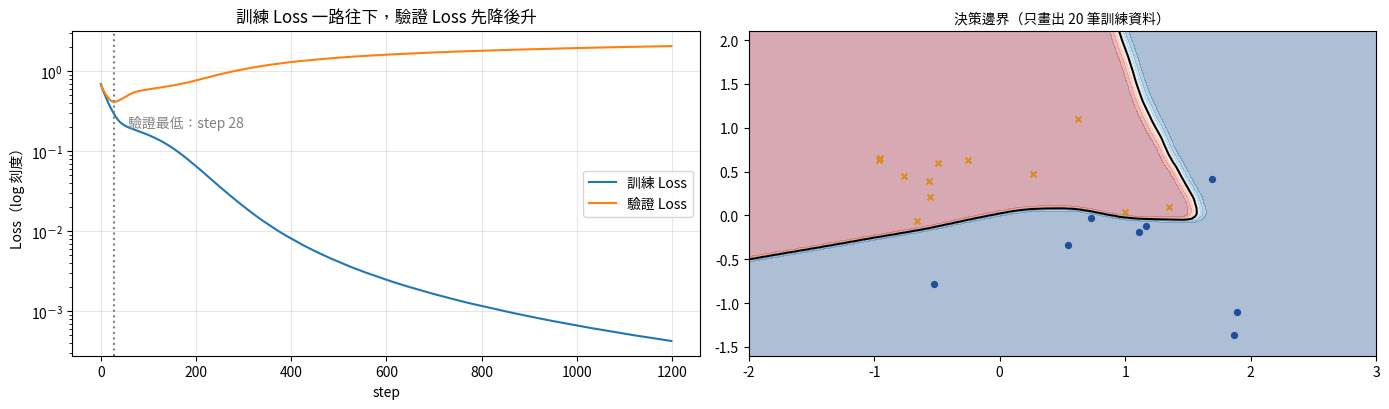

In [ ]:
# @title Lab 4-2：大模型＋少量資料
N_TRAIN, HIDDEN = 20, [128, 128]
Xtr, ytr, Xva, yva = make_split(N_TRAIN)
big = make_mlp(HIDDEN)
t0 = time.perf_counter()
tr, va = fit(big, Xtr, ytr, Xva, yva)
best = int(np.argmin(va))
print(f"模型 2 → {' → '.join(map(str, HIDDEN))} → 1：{n_params(big):,} 個參數｜訓練資料 {N_TRAIN} 筆（{time.perf_counter() - t0:.1f} 秒）")
print(f"最後：訓練 Loss {tr[-1]:.3f}｜驗證 Loss {va[-1]:.3f}")
print(f"驗證 Loss 最低在第 {best} 步：{va[best]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(tr, label="訓練 Loss"); axes[0].plot(va, label="驗證 Loss")
axes[0].axvline(best, color="gray", ls=":"); axes[0].annotate(f"驗證最低：step {best}", (best, va[best]), textcoords="offset points", xytext=(10, -18), color="gray")
axes[0].set_yscale("log"); axes[0].set_xlabel("step"); axes[0].set_ylabel("Loss（log 刻度）")
axes[0].legend(); axes[0].grid(alpha=.3); axes[0].set_title("訓練 Loss 一路往下，驗證 Loss 先降後升")
plot_boundary(axes[1], big, Xtr, ytr, "決策邊界（只畫出 20 筆訓練資料）")
plt.tight_layout(); plt.show()

,設定,參數量,最後訓練 Loss,最後驗證 Loss,驗證 − 訓練（差距）,驗證最低點 step
0,大模型＋20 筆,17025,0.000,2.071,2.071,28
1,小模型＋20 筆,17,0.275,0.530,0.255,683
2,大模型＋400 筆,17025,0.170,0.369,0.200,176


（三組共 7.0 秒）


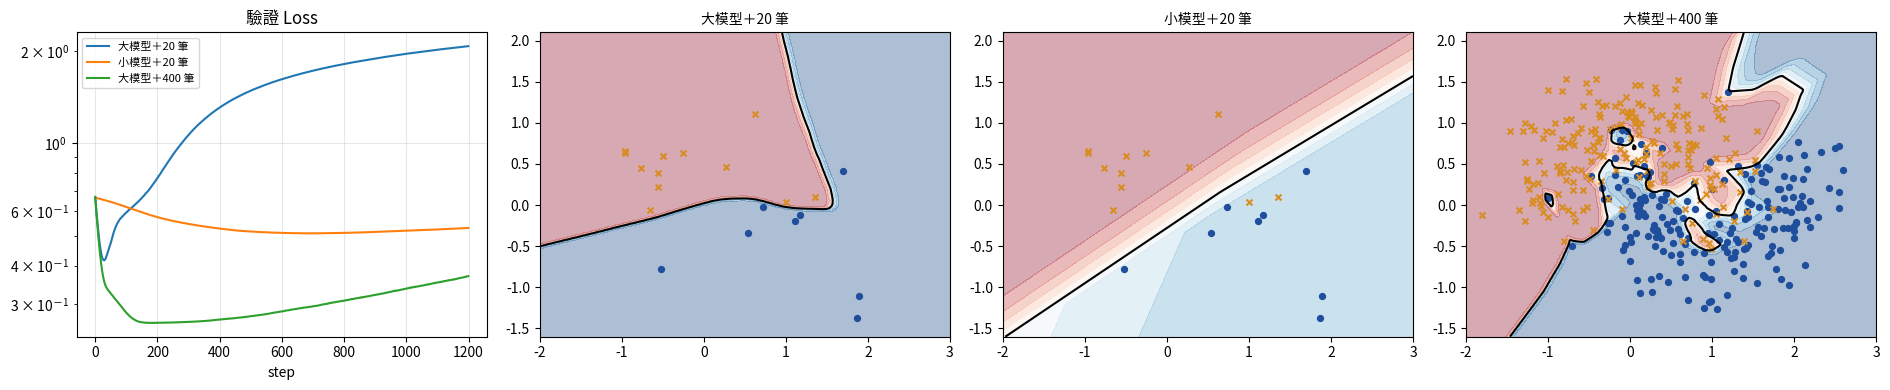

In [ ]:
# @title Lab 4-3：三種設定比較：大模型／小模型 × 少資料／多資料
CONFIGS = [("大模型＋20 筆", [128, 128], 20), ("小模型＋20 筆", [4], 20), ("大模型＋400 筆", [128, 128], 400)]
rows, curves, models = [], {}, {}
t0 = time.perf_counter()
for name, hidden, n in CONFIGS:
    Xtr_c, ytr_c, Xva_c, yva_c = make_split(n)
    m = make_mlp(hidden)
    tr_c, va_c = fit(m, Xtr_c, ytr_c, Xva_c, yva_c)
    curves[name], models[name] = (tr_c, va_c), (m, Xtr_c, ytr_c)
    rows.append({"設定": name, "參數量": n_params(m), "最後訓練 Loss": round(tr_c[-1], 3),
                 "最後驗證 Loss": round(va_c[-1], 3), "驗證 − 訓練（差距）": round(va_c[-1] - tr_c[-1], 3),
                 "驗證最低點 step": int(np.argmin(va_c))})
display(pd.DataFrame(rows))
print(f"（三組共 {time.perf_counter() - t0:.1f} 秒）")

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
for name, (tr_c, va_c) in curves.items():
    axes[0].plot(va_c, label=name)
axes[0].set_yscale("log"); axes[0].set_title("驗證 Loss"); axes[0].set_xlabel("step"); axes[0].legend(fontsize=8)
axes[0].grid(alpha=.3)
for ax, (name, (m, Xc, yc)) in zip(axes[1:], models.items()):
    plot_boundary(ax, m, Xc, yc, name)
plt.tight_layout(); plt.show()

### 🔧 動手改
改 `my_n_train` 或 `my_hidden`，一次只改一個。試試看：
- 大模型的訓練資料從 100 筆加到 400、1000 筆，「驗證 − 訓練」差距怎麼變？
- 固定 100 筆，隱藏層改成 `[16]`、`[4]`，差距怎麼變？

In [ ]:
# @title 🔧 動手改：一次只改一個
my_n_train, my_hidden = 100, [128, 128]     # TODO

Xtr_m, ytr_m, Xva_m, yva_m = make_split(my_n_train)
m_my = make_mlp(my_hidden)
tr_m, va_m = fit(m_my, Xtr_m, ytr_m, Xva_m, yva_m)
print(f"{my_n_train} 筆、隱藏層 {my_hidden}（{n_params(m_my):,} 個參數）")
print(f"最後訓練 Loss {tr_m[-1]:.3f}｜最後驗證 Loss {va_m[-1]:.3f}｜差距 {va_m[-1] - tr_m[-1]:.3f}")

100 筆、隱藏層 [128, 128]（17,025 個參數）
最後訓練 Loss 0.056｜最後驗證 Loss 0.868｜差距 0.812


### 👀 觀察
- 大模型＋20 筆：最後訓練 Loss、最後驗證 Loss、驗證最低點的 step：
- 小模型＋20 筆、大模型＋400 筆的差距各是多少：
- 我的動手改結果：

### 反思
1. 為什麼只看訓練 Loss 無法判斷模型好不好？（講義檢核題 2）
2. 「驗證最低點 step」提供了一個簡單的做法：訓練到那裡就停。你覺得這個做法有什麼風險？（提示：驗證資料也只有 400 筆。）
3. W08 的 LoRA 常常只用 10～30 張圖訓練。根據這個 Lab，你覺得最需要擔心什麼？

---
## Lab 5｜預訓練、微調與推論（講義 0.5–0.6）

### 問題
從零訓練一個大模型要大量資料和 GPU。為什麼別人預訓練好的權重可以拿來「繼續訓練」？只訓練一小部分參數（例如最後一層）夠不夠？訓練好之後拿來用，權重會不會偷偷改變？

### 實驗設計
| 階段 | 這個 Lab 的版本 | 對應真實世界 |
| --- | --- | --- |
| 預訓練 | 4,000 個點，分成 12 個區域（圓盤切成 6 個扇形 × 內外 2 圈） | 讀大量通用資料，學一般能力 |
| 新任務 | 只有 40 筆標註：判斷一個點是不是落在「小藍區域」（6 個扇形中相間的 3 個，像風車的葉片） | 少量資料的特定任務 |
| 比較 | (a) 從零訓練 (b) 從預訓練權重開始完整微調 (c) 凍結前面的層，只訓練最後一層 | (c) 是 LoRA「凍結、只學少量參數」的簡化版 |

網路分成兩段：

```text
body（前面的層）：2 個座標 → 64 → 64 → 12 個區域的機率      ← 預訓練學的就是這段
head（最後一層）：12 個區域的機率 → 是／不是小藍區域          ← 新任務要學的
```

三種做法用同樣的 40 筆資料、同樣的 optimizer、同樣 300 步，比較誰先在驗證資料上達到 90% 準確率。

### ✍️ 我的預測
1. (a)(b)(c) 哪一個最快達到 90% 驗證準確率？哪一個可能永遠達不到？
2. (c) 只訓練最後一層，可訓練參數大約占全部的百分之幾？
3. (c) 的表現會比 (b) 差很多嗎？

> 我的預測：
> 1.
> 2.
> 3.

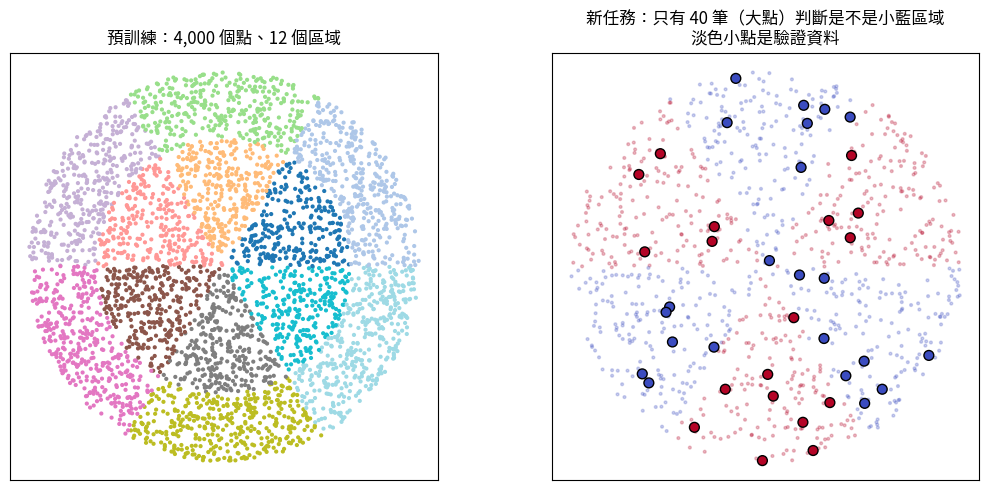

In [ ]:
# @title Lab 5-1：通用任務（12 區）與新任務（小藍區域）
import torch
import torch.nn as nn

torch.set_num_threads(min(4, os.cpu_count() or 1))
N_SECTORS, R_SPLIT = 6, 0.65
XIAOLAN_SECTORS = [0, 2, 4]                    # 6 個扇形中相間的 3 個：小藍區域


def sample_points(n, seed):
    rng = np.random.default_rng(seed)
    r, t = np.sqrt(rng.uniform(0, 1, n)), rng.uniform(0, 2 * np.pi, n)
    return np.column_stack([r * np.cos(t), r * np.sin(t)]).astype(np.float32)


def region_id(P):
    ang = np.arctan2(P[:, 1], P[:, 0]) % (2 * np.pi)
    sector = np.minimum((ang // (2 * np.pi / N_SECTORS)).astype(int), N_SECTORS - 1)
    ring = (np.linalg.norm(P, axis=1) > R_SPLIT).astype(int)
    return sector * 2 + ring                    # 0～11


def is_xiaolan(P):
    return np.isin(region_id(P) // 2, XIAOLAN_SECTORS).astype(int)


def to_t(P, y):
    return torch.tensor(P), torch.tensor(y, dtype=torch.long)


P_pre = sample_points(4000, seed=1);   P_pre_va = sample_points(1000, seed=2)
Xp, yp = to_t(P_pre, region_id(P_pre)); Xp_va, yp_va = to_t(P_pre_va, region_id(P_pre_va))
P_ft = sample_points(40, seed=3);      P_ft_va = sample_points(1000, seed=4)
Xf, yf = to_t(P_ft, is_xiaolan(P_ft))
Xf_va, yf_va = to_t(P_ft_va, is_xiaolan(P_ft_va))

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].scatter(*P_pre.T, c=region_id(P_pre), cmap="tab20", s=4)
axes[0].set_title("預訓練：4,000 個點、12 個區域")
axes[1].scatter(*P_ft_va.T, c=yf_va.numpy(), cmap="coolwarm", s=4, alpha=.25)
axes[1].scatter(*P_ft.T, c=yf.numpy(), cmap="coolwarm", s=50, edgecolors="k")
axes[1].set_title("新任務：只有 40 筆（大點）判斷是不是小藍區域\n淡色小點是驗證資料")
for ax in axes:
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

In [ ]:
# @title Lab 5-2：預訓練（迷你版）
class Net(nn.Module):
    """body：前面的層，輸出 12 區的分數；head：最後一層，把 12 區的機率組合成新任務的答案。"""
    def __init__(self, seed):
        super().__init__()
        torch.manual_seed(seed)
        self.body = nn.Sequential(nn.Linear(2, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 12))
        self.head = nn.Linear(12, 2)

    def forward(self, x):
        return self.head(self.body(x).softmax(dim=1))


def accuracy(model, X, y):
    with torch.no_grad():
        return (model(X).argmax(1) == y).float().mean().item()


def train_cls(model, X, y, Xva, yva, steps, lr=1e-2):
    params = [p for p in model.parameters() if p.requires_grad]      # 只交出「沒被凍結」的參數
    opt = torch.optim.Adam(params, lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    accs, losses = [], []
    for _ in range(steps):
        opt.zero_grad()
        loss = loss_fn(model(X), y)
        loss.backward(); opt.step()
        accs.append(accuracy(model, Xva, yva)); losses.append(loss.item())
    return accs, losses


t0 = time.perf_counter()
pretrained = Net(seed=0)
pre_acc, _ = train_cls(pretrained.body, Xp, yp, Xp_va, yp_va, steps=800)    # 預訓練只用到 body：12 區分類
print(f"預訓練完成：12 區分類的驗證準確率 {pre_acc[-1]:.1%}（{time.perf_counter() - t0:.1f} 秒）")

預訓練完成：12 區分類的驗證準確率 99.0%（3.8 秒）


（三種共 1.3 秒）


,可訓練參數,全部參數,達到 90% 的步數,最後驗證準確率,最後訓練 Loss,body 有沒有改,可訓練比例
(a) 從零訓練,5158,5158,300 步內沒達到,76.3%,0.283,有改,100.0%
(b) 完整微調,5158,5158,16,90.7%,0.04,有改,100.0%
(c) 只訓練最後一層,26,5158,24,99.6%,0.078,沒改（凍結）,0.5%


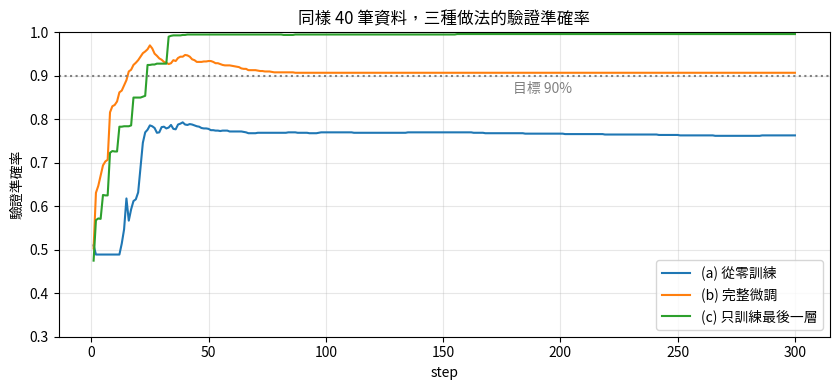

In [ ]:
# @title Lab 5-3：三種方式學新任務
STEPS_FT, TARGET = 300, 0.90


def make_variant(kind):
    m = Net(seed=123)                                  # 隨機權重；三種做法的 head 起點都一樣
    if kind in ("(b) 完整微調", "(c) 只訓練最後一層"):
        m.body.load_state_dict(pretrained.body.state_dict())   # 接上預訓練的 body
    if kind == "(c) 只訓練最後一層":
        for p in m.body.parameters():
            p.requires_grad_(False)                   # 凍結：這些權重不再更新
    return m


results, ft_models = {}, {}
t0 = time.perf_counter()
for kind in ["(a) 從零訓練", "(b) 完整微調", "(c) 只訓練最後一層"]:
    m = make_variant(kind)
    body_before = copy.deepcopy(m.body.state_dict())
    accs, losses = train_cls(m, Xf, yf, Xf_va, yf_va, steps=STEPS_FT)
    hit = next((i + 1 for i, a in enumerate(accs) if a >= TARGET), None)
    body_same = all(torch.equal(body_before[k], v) for k, v in m.body.state_dict().items())
    results[kind] = {"可訓練參數": sum(p.numel() for p in m.parameters() if p.requires_grad),
                     "全部參數": sum(p.numel() for p in m.parameters()),
                     f"達到 {TARGET:.0%} 的步數": hit if hit else f"{STEPS_FT} 步內沒達到",
                     "最後驗證準確率": f"{accs[-1]:.1%}", "最後訓練 Loss": round(losses[-1], 3),
                     "body 有沒有改": "沒改（凍結）" if body_same else "有改", "_accs": accs}
    ft_models[kind] = m
print(f"（三種共 {time.perf_counter() - t0:.1f} 秒）")

df_ft = pd.DataFrame({k: {kk: vv for kk, vv in v.items() if not kk.startswith("_")} for k, v in results.items()}).T
df_ft["可訓練比例"] = [f"{r['可訓練參數'] / r['全部參數']:.1%}" for r in results.values()]
display(df_ft)

fig, ax = plt.subplots(figsize=(8.5, 4))
for kind, r in results.items():
    ax.plot(np.arange(1, STEPS_FT + 1), r["_accs"], label=kind)
ax.axhline(TARGET, color="gray", ls=":"); ax.text(STEPS_FT * 0.6, TARGET - 0.04, f"目標 {TARGET:.0%}", color="gray")
ax.set_xlabel("step"); ax.set_ylabel("驗證準確率"); ax.set_ylim(0.3, 1.0); ax.legend(); ax.grid(alpha=.3)
ax.set_title("同樣 40 筆資料，三種做法的驗證準確率"); plt.tight_layout(); plt.show()

### 看圖說話
- (a) 從零訓練：40 筆資料不夠它從頭學會「哪裡是哪一區」，準確率卡在 70% 多。
- (b) 完整微調：起步最快，但衝到最高點之後又往下掉。只有 40 筆資料，卻讓全部 5,158 個參數一起改，預訓練學到的區域特徵也被改動了，很可能開始過擬合（回想 Lab 4）。
- (c) 只訓練最後一層：前面的層保持預訓練的樣子，只學「12 區裡哪幾區算小藍區域」，26 個參數就夠，而且最穩。

這是刻意設計過的玩具任務：新任務需要的特徵，剛好就是預訓練學到的特徵。真實情況不一定這麼理想，(b) 和 (c) 誰比較好要看任務和資料量。

### 和 W08 的連結
- (b) 完整微調：所有權重都跟著更新。
- (c) 凍結前面的層，只訓練最後一層：程式裡就是 `requires_grad_(False)`，再把沒凍結的參數交給 optimizer。W08 的 LoRA 也是先凍結原本的 W，差別在於 LoRA 不只動最後一層，而是在原本的層旁邊加上一小組新參數 $B$、$A$ 來學。
- 這個 Lab 的「預訓練」只有 4,000 個點、幾秒鐘。真正的預訓練是幾千億個 Token 或幾十億張圖，所以一般人幾乎都從別人預訓練好的權重開始。

### 推論：權重固定，拿模型來用
訓練完成後，拿模型來回答問題叫做 **推論（Inference）**。推論時沒有正確答案、沒有 Loss、沒有 `backward()`，也沒有 `optimizer.step()`，所以權重不會變。

In [ ]:
# @title Lab 5-4：推論 1,000 次，權重有沒有變？
model = ft_models["(b) 完整微調"]
model.eval()
x_new = torch.tensor([[0.5, 0.5], [-0.3, 0.8], [0.1, -0.9]])
before = copy.deepcopy(model.state_dict())

with torch.no_grad():                       # 推論：不建立計算梯度用的紀錄
    out_first = model(x_new).softmax(1)
    for _ in range(1000):
        model(x_new)
    out_last = model(x_new).softmax(1)

same_weights = all(torch.equal(before[k], v) for k, v in model.state_dict().items())
print("第 1 次推論，是小藍區域的機率：", np.round(out_first[:, 1].numpy(), 4))
print("第 1002 次推論，同樣的輸入：    ", np.round(out_last[:, 1].numpy(), 4))
print("兩次輸出完全相同：", torch.equal(out_first, out_last))
print("推論 1,000 次後權重完全沒變：", same_weights)
print("推論輸出 requires_grad：", out_first.requires_grad, "→ 沒有梯度，就不會有更新")

第 1 次推論，是小藍區域的機率： [0.9613 0.0347 0.9521]
第 1002 次推論，同樣的輸入：     [0.9613 0.0347 0.9521]
兩次輸出完全相同： True
推論 1,000 次後權重完全沒變： True
推論輸出 requires_grad： False → 沒有梯度，就不會有更新


### 聊天會改變模型嗎？（概念示範）
講義 0.6：「你在對話框裡打的字，不會改變模型本身。」模型「記得」你剛才說的話，是因為整段對話會一起送進去當輸入。

下面這格不是真的語言模型，只示範資料怎麼流動：每一輪，送進模型的輸入是「之前所有對話＋這一句」；權重從頭到尾沒有被碰過。我們用上面 (b) 模型的權重算一個「指紋」（所有權重加總），確認它在對話前後一樣。

In [ ]:
# @title Lab 5-5：對話紀錄是「輸入」，不是「權重」
def weight_fingerprint(m):
    return sum(float(p.detach().double().sum()) for p in m.parameters())


def build_model_input(history, message):
    return "\n".join(history + [f"使用者：{message}"])


fp_start = weight_fingerprint(model)
history = []
for turn, msg in enumerate(["我叫小明。", "我最喜歡的角色是小藍。", "我叫什麼名字？"], start=1):
    model_input = build_model_input(history, msg)
    reply = "你叫小明。" if "什麼名字" in msg else "好的。"   # 假裝的回覆：答案就在 model_input 裡
    history += [f"使用者：{msg}", f"模型：{reply}"]
    print(f"第 {turn} 輪｜送進模型的輸入有 {len(model_input):>2} 個字｜權重指紋 {weight_fingerprint(model):.6f}")

print("\n第 3 輪實際送進模型的輸入：\n" + model_input)
new_chat_input = build_model_input([], "我叫什麼名字？")
print("\n開新對話後送進模型的輸入：\n" + new_chat_input, "\n→ 輸入裡已經沒有「小明」，模型無從得知。")
assert weight_fingerprint(model) == fp_start

第 1 輪｜送進模型的輸入有  9 個字｜權重指紋 104.201056
第 2 輪｜送進模型的輸入有 32 個字｜權重指紋 104.201056
第 3 輪｜送進模型的輸入有 51 個字｜權重指紋 104.201056

第 3 輪實際送進模型的輸入：
使用者：我叫小明。
模型：好的。
使用者：我最喜歡的角色是小藍。
模型：好的。
使用者：我叫什麼名字？

開新對話後送進模型的輸入：
使用者：我叫什麼名字？ 
→ 輸入裡已經沒有「小明」，模型無從得知。


### 🔧 動手改
1. 把 `P_ft = sample_points(40, seed=3)` 的 40 改成 400，重跑 Lab 5-1 與 5-3。(a) 從零訓練追上來了嗎？
2. 只把 `STEPS_FT` 改成 60，重跑 Lab 5-3。哪一種做法受影響最大？

### 👀 觀察
- 三種做法達到 90% 的步數與最後準確率：
- (c) 的可訓練參數與比例：
- 推論 1,000 次後，權重與輸出有沒有變：
- 動手改的結果：

### 反思
1. 你在聊天機器人裡糾正它一個錯誤，下次開新對話它還會記得嗎？用 Lab 5-5 的輸出說明。（講義檢核題 3）
2. 有些聊天服務有「記憶」功能，開新對話也記得你的名字。根據這個 Lab，你猜這類功能比較可能是改了權重，還是把記下來的內容放進輸入？

---
## Lab 6｜玩具語言模型：一個 Token 接一個 Token（講義 0.7）

### 問題
大語言模型怎麼「寫」出一段話？為什麼它有時候會一本正經地答錯？

### 原理
LLM 在推論時只做一件事：根據前面的文字，算出下一個 **Token** 的機率，挑一個接上去，再重複。

這個 Lab 的模型非常陽春：

- Token＝一個字（字元層級）。
- **Bigram 模型**：只看前 1 個字。查「訓練文字裡，這個字後面接過哪些字、各幾次」，換算成機率。
- **Trigram 模型**：看前 2 個字，其餘做法相同。
- 「訓練」就是數次數，數出來的次數表就是這個模型的「權重」。

真正的 LLM 用神經網路與幾千億個 Token 訓練，看得到前面很長一段文字，但「算機率 → 挑一個 → 接上去」的迴圈是同一套。語料是我們自己寫的 45 句課程相關句子。

### ✍️ 我的預測
1. 輸入「多媒體系統是一門」，下一個字最可能是什麼？
2. 每次都挑機率最高的字（Greedy），一直生成下去，會發生什麼事？
3. 問它「W08作業的繳交期限是」，語料裡沒有這個資訊。它會回答「我不知道」嗎？

> 我的預測：
> 1.
> 2.
> 3.

In [ ]:
# @title Lab 6-1：語料（自己寫的 45 句）與「訓練」＝數次數
from collections import Counter, defaultdict

CORPUS = """
多媒體系統是一門結合影像、聲音與互動的課。
這門課結合影像處理、聲音處理與生成模型。
影像是由很多像素組成的。
每個像素都有紅、綠、藍三個數值。
聲音是空氣的振動，電腦用取樣把聲音變成數字。
取樣率越高，聲音的細節越多。
影片是一張一張的影像依序播放。
壓縮可以讓影像和影片的檔案變小。
模型是一個把輸入變成輸出的函數。
模型的行為由權重決定。
訓練模型就是調整權重，讓 Loss 變小。
權重是一張一張的數字表。
神經元把輸入乘上權重，加起來，再加上偏差值。
一層神經網路就是一次矩陣運算。
學習率太大，訓練會衝過頭。
學習率太小，訓練會走很久。
驗證資料可以檢查模型有沒有過擬合。
預訓練讓模型從大量資料學到一般能力。
微調用少量資料讓模型適配新的任務。
推論時權重固定，模型只負責回答。
語言模型一次預測一個 Token。
語言模型根據前面的文字預測下一個字。
擴散模型從雜訊開始，一步一步去掉雜訊。
Prompt 告訴模型要生成什麼樣的影像。
生成影像時，固定 Seed 可以重現結果。
LoRA 凍結原本的權重，只學一個小小的更新量。
W08 要學 LoRA 與影像一致性。
W07 作業的繳交期限是第八週上課前。
期末專題的繳交期限是第十八週。
期中報告的繳交期限是第十週。
作業要上傳到教學平台。
上課前請先打開 Colab。
Colab 可以在瀏覽器裡執行 Python。
這門課的作業都用 Colab 完成。
影像生成模型可以畫出原創角色。
小藍是我們的原創角色。
小藍有短黑髮、圓眼鏡和深藍帽T。
我們希望模型每次都畫出同一個小藍。
聲音和影像都可以用數字表示。
多媒體系統也會討論資料的授權與隱私。
好的資料比更多的資料重要。
檢索增強生成會先查資料再回答。
查到的資料寫錯，回答也會跟著錯。
多媒體系統的期末專題要做一段影像故事。
影像故事需要角色、風格和構圖都一致。
"""
SENTENCES = [s.replace(" ", "") for s in CORPUS.strip().split("\n")]   # 為了簡化，先拿掉空白
TEXT = "".join(SENTENCES)                                               # 每句都以「。」結尾


def train_ngram(text, order):
    """order = 1 → Bigram（看前 1 個字）；order = 2 → Trigram（看前 2 個字）。"""
    counts = defaultdict(Counter)
    for i in range(order, len(text)):
        counts[text[i - order:i]][text[i]] += 1
    return counts


bigram = train_ngram(TEXT, 1)
trigram = train_ngram(TEXT, 2)
print(f"語料：{len(SENTENCES)} 句、{len(TEXT)} 個 Token（字），不同的字有 {len(set(TEXT))} 種")
print(f"Bigram 記了 {len(bigram)} 種前文、Trigram 記了 {len(trigram)} 種前文")
print("「影」後面接過：", dict(bigram["影"]))

語料：45 句、736 個 Token（字），不同的字有 277 種
Bigram 記了 277 種前文、Trigram 記了 552 種前文
「影」後面接過： {'像': 12, '片': 2}


前文「多媒體系統是一門」→ Bigram 只看「門」，下一個 Token 的機率（前 5 名）：
  課 67%、結 33%
前文「影」→ Bigram 只看「影」，下一個 Token 的機率（前 5 名）：
  像 86%、片 14%
前文「權」→ Bigram 只看「權」，下一個 Token 的機率（前 5 名）：
  重 86%、與 14%

同一個前文，Trigram 看最後兩個字「一門」： 結 100%


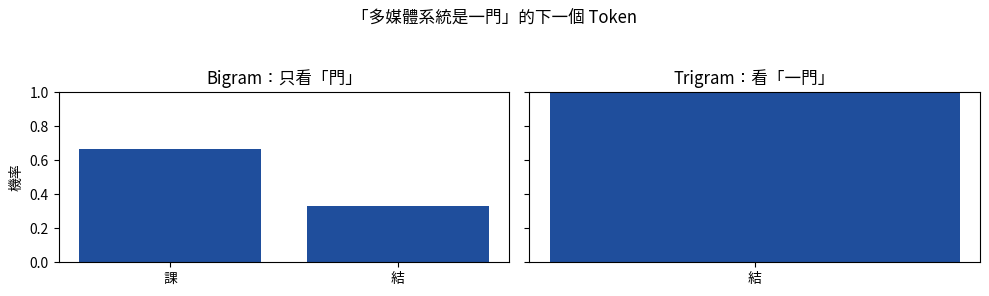

In [ ]:
# @title Lab 6-2：下一個 Token 的機率表
def next_probs(prefix, model_order=1, temperature=1.0):
    """依前文最後 order 個字查表。Trigram 查不到時退回 Bigram。回傳依機率排序的 Series。"""
    table = trigram if model_order == 2 else bigram
    ctx = prefix[-model_order:]
    if ctx not in table and model_order == 2:
        return next_probs(prefix, 1, temperature)
    if ctx not in table:
        raise KeyError(f"語料裡沒看過「{ctx}」")
    c = pd.Series(table[ctx], dtype=float)
    p = c ** (1.0 / temperature)                 # Temperature：<1 讓高的更高，>1 讓分布更平
    return (p / p.sum()).sort_values(ascending=False)


for prefix in ["多媒體系統是一門", "影", "權"]:
    pr = next_probs(prefix, 1)
    print(f"前文「{prefix}」→ Bigram 只看「{prefix[-1]}」，下一個 Token 的機率（前 5 名）：")
    print("  " + "、".join(f"{t} {p:.0%}" for t, p in pr.head(5).items()))

pr_tri = next_probs("多媒體系統是一門", 2)
print()
print("同一個前文，Trigram 看最後兩個字「一門」：", "、".join(f"{t} {p:.0%}" for t, p in pr_tri.items()))

fig, axes = plt.subplots(1, 2, figsize=(10, 2.8), sharey=True)
for ax, (name, pr_) in zip(axes, [("Bigram：只看「門」", next_probs("多媒體系統是一門", 1)), ("Trigram：看「一門」", pr_tri)]):
    ax.bar(pr_.index[:8], pr_.values[:8], color="#1f4e9c"); ax.set_title(name); ax.set_ylim(0, 1)
axes[0].set_ylabel("機率")
plt.suptitle("「多媒體系統是一門」的下一個 Token", y=1.04); plt.tight_layout(); plt.show()

In [ ]:
# @title Lab 6-3：生成就是一個迴圈：挑一個 Token → 接上去 → 再預測
def generate(prefix, n=30, mode="greedy", temperature=1.0, order=1, seed=0, stop="。"):
    rng = np.random.default_rng(seed)
    out = prefix
    for _ in range(n):
        pr = next_probs(out, order, temperature)
        tok = pr.index[0] if mode == "greedy" else rng.choice(pr.index.to_numpy(), p=pr.to_numpy())
        out += tok
        if stop and tok == stop:
            break
    return out


PREFIX = "多媒體系統是一門"
print("【Greedy，每次都選機率最高的，不在句號停】")
print("  Bigram ：", generate(PREFIX, n=40, mode="greedy", order=1, stop=None))
print("  Trigram：", generate(PREFIX, n=40, mode="greedy", order=2, stop=None))
print("\n【Sampling，依機率抽籤，到句號停；Bigram】")
for T in [0.5, 1.0, 1.5]:
    for s in range(3):
        print(f"  T = {T}，seed {s}：", generate(PREFIX, n=40, mode="sample", temperature=T, order=1, seed=s))

【Greedy，每次都選機率最高的，不在句號停】
  Bigram ： 多媒體系統是一門課前面的資料可以讓模型從大，訓練會衝過頭。影像素組成模型從大，訓練會衝過頭。影像
  Trigram： 多媒體系統是一門結合影像故事。影像故事。影像故事。影像故事。影像故事。影像故事。影像故事。影像故

【Sampling，依機率抽籤，到句號停；Bigram】
  T = 0.5，seed 0： 多媒體系統是一門課前面的文字表示。
  T = 0.5，seed 1： 多媒體系統是一門課的資料讓模型就是一致。
  T = 0.5，seed 2： 多媒體系統是一門課前請先查到一個小。
  T = 1.0，seed 0： 多媒體系統是一門課前面的權與影像依序播放。
  T = 1.0，seed 1： 多媒體系統是一門課的繳交期限是一致性。
  T = 1.0，seed 2： 多媒體系統是一門課前請先查到一個小，再加起來，模型一張一張的原本的授權重，訓練讓影像和影像。
  T = 1.5，seed 0： 多媒體系統是一門結合影像一般能力。
  T = 1.5，seed 1： 多媒體系統是一門課的繳交期限是第十八週。
  T = 1.5，seed 2： 多媒體系統是一門課前請先查到一個像和深藍有過頭。


In [ ]:
# @title Lab 6-4：Temperature 怎麼改變機率表
prefix_t = "像"
table_T = pd.DataFrame({f"T = {T}": next_probs(prefix_t, 1, T) for T in [0.5, 1.0, 2.0]}).fillna(0)
table_T = table_T.sort_values("T = 1.0", ascending=False).head(6)
display((table_T * 100).round(1).astype(str) + "%")
print(f"前文最後一個字是「{prefix_t}」：T 小，前幾名更集中；T 大，冷門的字也比較有機會被抽到。")

,T = 0.5,T = 1.0,T = 2.0
素,22.2%,14.3%,11.0%
故,22.2%,14.3%,11.0%
處,5.6%,7.1%,7.8%
、,5.6%,7.1%,7.8%
是,5.6%,7.1%,7.8%
依,5.6%,7.1%,7.8%


前文最後一個字是「像」：T 小，前幾名更集中；T 大，冷門的字也比較有機會被抽到。


### 幻覺：語料裡沒有的事，它照樣接得很順
講義 0.7：LLM 的工作是接出看起來合理的下一段文字，它不會去查資料庫。我們的語料完全沒寫 W08 作業的期限，看看模型怎麼「回答」。

In [ ]:
# @title Lab 6-5：問一個語料裡沒有答案的問題
Q_PREFIX = "W08作業的繳交期限是"
print("語料裡和 W08 有關的句子：", [s for s in SENTENCES if "W08" in s])
print("語料裡寫到「繳交期限」的句子：", [s for s in SENTENCES if "期限" in s])
print()
print("Trigram＋Greedy：", generate(Q_PREFIX, n=20, mode="greedy", order=2))
for s in range(5):
    print(f"Trigram＋Sampling（seed {s}）：", generate(Q_PREFIX, n=20, mode="sample", order=2, seed=s))
print("\n前文「限是」之後的機率：", "、".join(f"{t} {p:.0%}" for t, p in next_probs(Q_PREFIX, 2).items()))

語料裡和 W08 有關的句子： ['W08要學LoRA與影像一致性。']
語料裡寫到「繳交期限」的句子： ['W07作業的繳交期限是第八週上課前。', '期末專題的繳交期限是第十八週。', '期中報告的繳交期限是第十週。']

Trigram＋Greedy： W08作業的繳交期限是第十八週上課前。
Trigram＋Sampling（seed 0）： W08作業的繳交期限是第十八週。
Trigram＋Sampling（seed 1）： W08作業的繳交期限是第八週。
Trigram＋Sampling（seed 2）： W08作業的繳交期限是第十週。
Trigram＋Sampling（seed 3）： W08作業的繳交期限是第十週。
Trigram＋Sampling（seed 4）： W08作業的繳交期限是第十週。

前文「限是」之後的機率： 第 100%


模型沒有「不知道」這個選項。Trigram 只看得到最後兩個字「限是」，就接上語料裡常接在後面的字，答出一個看起來很像真的期限。這些答案其實來自 W07、期中報告或期末專題的句子，有的甚至是兩句拼起來的。這就是 **幻覺（Hallucination）**。

### 🔧 動手改：把答案加進語料，重新「訓練」
在 `NEW_SENTENCE` 寫一句 W08 的期限（下面先放一句示範用的虛構內容），重新數次數，再問一次。執行前先預測：加一句之後，Greedy 一定會答對嗎？

In [ ]:
# @title 🔧 動手改：改訓練資料 → 重新訓練 → 再問一次
NEW_SENTENCE = "W08作業的繳交期限是第九週上課前。"     # TODO: 示範用的虛構內容，可以改寫或多加幾句
trigram_backup = trigram
trigram = train_ngram(TEXT + NEW_SENTENCE, 2)           # 「重新訓練」＝重新數次數
print("加入後，前文「限是」之後的機率：", "、".join(f"{t} {p:.0%}" for t, p in next_probs(Q_PREFIX, 2).items()))
print("Trigram＋Greedy：", generate(Q_PREFIX, n=20, mode="greedy", order=2))
for s in range(5):
    print(f"Trigram＋Sampling（seed {s}）：", generate(Q_PREFIX, n=20, mode="sample", order=2, seed=s))
trigram = trigram_backup                                # 還原，避免影響後面的格子

加入後，前文「限是」之後的機率： 第 100%
Trigram＋Greedy： W08作業的繳交期限是第十八週上課前。
Trigram＋Sampling（seed 0）： W08作業的繳交期限是第十八週。
Trigram＋Sampling（seed 1）： W08作業的繳交期限是第九週上課前請先打開Colab可以重現結
Trigram＋Sampling（seed 2）： W08作業的繳交期限是第十週。
Trigram＋Sampling（seed 3）： W08作業的繳交期限是第十週。
Trigram＋Sampling（seed 4）： W08作業的繳交期限是第八週上課前請先打開Colab可以用數字


### 👀 觀察
- 「多媒體系統是一門」的下一個 Token 前兩名與機率：
- Greedy 生成時出現了什麼現象：
- T = 0.5 和 T = 1.5 的生成結果差在哪裡：
- 問「W08作業的繳交期限是」，模型答了什麼？答案是從哪幾句語料拼來的：
- 加入一句正確資料後，Greedy 答對了嗎：

### 反思
1. 動手改裡，我們把一句話加進語料、重新訓練，模型還是不一定答對。對照講義 0.8「拿課程資料去微調模型……很難確認它真的記住了」，說說你的看法。
2. 真正的 LLM 比 Trigram 強很多，為什麼仍然會有幻覺？用「它的工作是接下一個 Token」來解釋。

---
## Lab 7｜玩具 RAG：先查資料，再回答（講義 0.8）

### 問題
Lab 6 的模型不知道 W08 的期限，只好亂接。把課程資料拿去重新訓練又貴又不可靠，而且資料每週都在更新。可不可以不改權重，讓模型回答它沒學過的資料？

### 原理
**RAG（Retrieval-Augmented Generation，檢索增強生成）** 分成三步：

```text
1. 檢索：從課程講義找出和問題最相關的段落
2. 組 Prompt：把段落和問題一起放進輸入
3. 生成：模型根據放進來的資料回答（推論，權重不變）
```

這個 Lab 的每一步都用最簡單的做法：

- **檢索**：TF-IDF。把每段文字切成一個字、兩個字、三個字一組的片段（字元 n-gram，中文不需要斷詞），出現在越少段落的片段越有代表性。再用餘弦相似度（Cosine Similarity）比較問題和每一段有多像。
- **生成**：不接任何 LLM，也不需要 API Key。用一個「抽取式」的小規則：從排名第一的段落挑出和問題最相關的句子，附上出處。

下面的講義段落是 **示範用的虛構內容**，實際規定以老師在課堂上公告的為準。

### ✍️ 我的預測
1. 問「W08 要繳交什麼？」，排名第一的會是哪一段？第二名呢？
2. 換個說法問「第八週要交哪些東西？」，檢索還找得到 W08 那一段嗎？
3. 把 W08 的期限改掉之後，要重新訓練什麼東西，答案才會跟著變？

> 我的預測：
> 1.
> 2.
> 3.

In [ ]:
# @title Lab 7-1：課程講義（示範用的虛構內容）與 TF-IDF 檢索
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

DOCS = [
    {"title": "課程簡介", "text": "多媒體系統介紹影像、聲音與生成模型的基本原理。每週都有一份 Colab 實作。"},
    {"title": "成績計算", "text": "學期成績由每週實作 40%、期中報告 20%、期末專題 40% 組成。"},
    {"title": "W07 繳交規定", "text": "W07 要繳交擴散模型實驗的 Notebook，檔名為 W07_學號_姓名.ipynb。期限是第八週上課前。"},
    {"title": "W08 繳交規定", "text": "W08 要繳交執行完成的 LoRA 實作 Notebook（保留輸出），檔名為 W08_學號_姓名.ipynb。內容需包含 Dataset Card、Visual Specification 與一致性評分表。期限是 W09 上課前。"},
    {"title": "W08-0 先修", "text": "W08-0 是先修單元，介紹神經網路、訓練、推論與 RAG。先修 Notebook 請在 W08 上課前完成並上傳。"},
    {"title": "遲交規定", "text": "作業遲交一天扣 10 分，超過一週不予受理。生病或公假請附證明。"},
    {"title": "AI 使用規定", "text": "可以使用生成式 AI 協助寫程式，但必須在 Notebook 最後填寫 AI 協作紀錄，說明採用、修改或拒絕了哪些建議。"},
    {"title": "Colab 環境", "text": "W08 的必做實驗只需要 CPU。選做的影像生成需要 T4 GPU，分配不到時可以改天再跑。"},
    {"title": "期中報告", "text": "期中報告在 W10 繳交，主題是分析一個多媒體作品用到的技術。"},
    {"title": "期末專題", "text": "期末專題要做一段六張影像的故事，角色、風格與構圖需保持一致，W18 發表。"},
    {"title": "字型設定", "text": "圖表的中文顯示成方框時，重新執行環境設定那一格即可。"},
    {"title": "請假規定", "text": "請假請在上課前透過校務系統申請，並寄信告知助教。"},
    {"title": "Office Hour", "text": "助教的 Office Hour 是每週三下午，地點在系館 501 教室。"},
]


def build_index(docs):
    vec = TfidfVectorizer(analyzer="char", ngram_range=(1, 3))     # 一到三個字的片段，中文不用斷詞
    mat = vec.fit_transform([d["title"] + "：" + d["text"] for d in docs])
    return vec, mat


def retrieve(question, vec, mat, docs, k=3):
    sims = cosine_similarity(vec.transform([question]), mat).ravel()
    top = np.argsort(-sims)[:k]
    return [(int(i), float(sims[i])) for i in top]


def show_hits(question, hits, docs):
    print(f"問題：{question}")
    display(pd.DataFrame([{"排名": r + 1, "相似度": round(s, 3), "段落": docs[i]["title"], "內容": docs[i]["text"][:40] + "…"}
                          for r, (i, s) in enumerate(hits)]))


vec, mat = build_index(DOCS)
print(f"講義共 {len(DOCS)} 段；TF-IDF 詞彙表有 {len(vec.vocabulary_)} 個片段")
QUESTION = "W08 要繳交什麼？"
hits = retrieve(QUESTION, vec, mat, DOCS)
show_hits(QUESTION, hits, DOCS)

講義共 13 段；TF-IDF 詞彙表有 1256 個片段
問題：W08 要繳交什麼？


,排名,相似度,段落,內容
0,1,0.337,W08 繳交規定,W08 要繳交執行完成的 LoRA 實作 Notebook（保留輸出），檔名為 …
1,2,0.258,W07 繳交規定,W07 要繳交擴散模型實驗的 Notebook，檔名為 W07_學號_姓名.ip…
2,3,0.236,W08-0 先修,W08-0 是先修單元，介紹神經網路、訓練、推論與 RAG。先修 Noteboo…


In [ ]:
# @title Lab 7-2：組 Prompt＋抽取式「生成」
def build_prompt(question, hits, docs):
    ctx = "\n".join(f"[資料{r + 1}｜{docs[i]['title']}] {docs[i]['text']}" for r, (i, _) in enumerate(hits))
    return f"請只根據下面的資料回答問題，並標出資料編號；資料裡沒有就回答「資料中沒有」。\n\n{ctx}\n\n問題：{question}\n回答："


def char_bigrams(s):
    s = re.sub(r"[\s，。？！、：（）]", "", s.lower())
    return {s[i:i + 2] for i in range(len(s) - 1)}


def toy_generate(question, hits, docs, min_overlap=1):
    """抽取式小規則：在第 1 名段落裡，挑和問題共用最多「兩字片段」的句子。
    段落標題已經出現過的片段（例如 W08、繳交）每句都沾得上邊，先不計分，避免每次都選第一句。
    這裡沒有任何權重會被更新。"""
    i, _ = hits[0]
    sents = [s for s in re.split(r"(?<=[。])", docs[i]["text"]) if s.strip()]
    q, title = char_bigrams(question), char_bigrams(docs[i]["title"])
    best = max(sents, key=lambda s: (len((q - title) & char_bigrams(s)), len(q & char_bigrams(s))))
    if len(q & char_bigrams(best)) < min_overlap:
        return "資料中沒有。"
    return f"{best}（出處：資料1｜{docs[i]['title']}）"


prompt = build_prompt(QUESTION, hits, DOCS)
print("===== 送進模型的 Prompt =====")
print(prompt)
print("\n===== 玩具生成器的回答 =====")
print(toy_generate(QUESTION, hits, DOCS))

===== 送進模型的 Prompt =====
請只根據下面的資料回答問題，並標出資料編號；資料裡沒有就回答「資料中沒有」。

[資料1｜W08 繳交規定] W08 要繳交執行完成的 LoRA 實作 Notebook（保留輸出），檔名為 W08_學號_姓名.ipynb。內容需包含 Dataset Card、Visual Specification 與一致性評分表。期限是 W09 上課前。
[資料2｜W07 繳交規定] W07 要繳交擴散模型實驗的 Notebook，檔名為 W07_學號_姓名.ipynb。期限是第八週上課前。
[資料3｜W08-0 先修] W08-0 是先修單元，介紹神經網路、訓練、推論與 RAG。先修 Notebook 請在 W08 上課前完成並上傳。

問題：W08 要繳交什麼？
回答：

===== 玩具生成器的回答 =====
W08 要繳交執行完成的 LoRA 實作 Notebook（保留輸出），檔名為 W08_學號_姓名.ipynb。（出處：資料1｜W08 繳交規定）


### 失敗案例：檢索找錯段落，答案就跟著錯
講義 0.8 提醒：「檢索找錯段落，答案就會錯。」我們的 TF-IDF 只比對字面，它不知道「第八週」就是「W08」。偏偏 W07 那一段寫著「期限是第八週上課前」，字面上最像。

In [ ]:
# @title Lab 7-3：換個說法問
for q in ["第八週要交哪些東西？", "W08 要交哪些東西？"]:
    h = retrieve(q, vec, mat, DOCS)
    show_hits(q, h, DOCS)
    print("回答：", toy_generate(q, h, DOCS), "\n")

問題：第八週要交哪些東西？


,排名,相似度,段落,內容
0,1,0.174,W07 繳交規定,W07 要繳交擴散模型實驗的 Notebook，檔名為 W07_學號_姓名.ip…
1,2,0.066,AI 使用規定,可以使用生成式 AI 協助寫程式，但必須在 Notebook 最後填寫 AI 協…
2,3,0.045,遲交規定,作業遲交一天扣 10 分，超過一週不予受理。生病或公假請附證明。…


回答： 期限是第八週上課前。（出處：資料1｜W07 繳交規定） 

問題：W08 要交哪些東西？


,排名,相似度,段落,內容
0,1,0.269,W08 繳交規定,W08 要繳交執行完成的 LoRA 實作 Notebook（保留輸出），檔名為 …
1,2,0.241,W08-0 先修,W08-0 是先修單元，介紹神經網路、訓練、推論與 RAG。先修 Noteboo…
2,3,0.149,W07 繳交規定,W07 要繳交擴散模型實驗的 Notebook，檔名為 W07_學號_姓名.ip…


回答： W08 要繳交執行完成的 LoRA 實作 Notebook（保留輸出），檔名為 W08_學號_姓名.ipynb。（出處：資料1｜W08 繳交規定） 



### 更新資料：不訓練，答案就變了
假設老師公告 W08 延期一週（示範用的虛構情境）。我們只改講義那一段文字、重建索引，**沒有任何訓練**，再問一次。

In [ ]:
# @title Lab 7-4：改文件 → 重建索引 → 答案改變
Q_DEADLINE = "W08 的繳交期限是什麼時候？"
h_old = retrieve(Q_DEADLINE, vec, mat, DOCS)
print("更新前：", toy_generate(Q_DEADLINE, h_old, DOCS))

DOCS_V2 = copy.deepcopy(DOCS)
for d in DOCS_V2:
    if d["title"] == "W08 繳交規定":
        d["text"] = d["text"].replace("期限是 W09 上課前。", "期限是 W10 上課前（老師公告延期一週）。")
vec2, mat2 = build_index(DOCS_V2)          # 重建索引只是重新整理文件，不是訓練模型
h_new = retrieve(Q_DEADLINE, vec2, mat2, DOCS_V2)
print("更新後：", toy_generate(Q_DEADLINE, h_new, DOCS_V2))
print("\n對照 Lab 6-5：沒有檢索的玩具語言模型，只能從語料裡拼出別份作業的期限。")

更新前： 期限是 W09 上課前。（出處：資料1｜W08 繳交規定）
更新後： 期限是 W10 上課前（老師公告延期一週）。（出處：資料1｜W08 繳交規定）

對照 Lab 6-5：沒有檢索的玩具語言模型，只能從語料裡拼出別份作業的期限。


### 🔧 動手改
1. 自己問一個問題，例如「遲交會怎樣？」「可以用 ChatGPT 嗎？」，看檢索與回答對不對。
2. 試著讓 Lab 7-3 的「第八週要交哪些東西？」答對。一次只改一個地方，例如：在 `W08 繳交規定` 的 `title` 補上「第八週」，或把 `k` 改大。

In [ ]:
# @title 🔧 動手改：問你自己的問題
my_question = "遲交會怎樣？"          # TODO
my_k = 3                              # TODO
h_my = retrieve(my_question, vec, mat, DOCS, k=my_k)
show_hits(my_question, h_my, DOCS)
print("回答：", toy_generate(my_question, h_my, DOCS))

問題：遲交會怎樣？


,排名,相似度,段落,內容
0,1,0.322,遲交規定,作業遲交一天扣 10 分，超過一週不予受理。生病或公假請附證明。…
1,2,0.047,W07 繳交規定,W07 要繳交擴散模型實驗的 Notebook，檔名為 W07_學號_姓名.ip…
2,3,0.031,期中報告,期中報告在 W10 繳交，主題是分析一個多媒體作品用到的技術。…


回答： 作業遲交一天扣 10 分，超過一週不予受理。（出處：資料1｜遲交規定）


### 👀 觀察
- 「W08 要繳交什麼？」的前 3 名段落與相似度：
- 「第八週要交哪些東西？」排名第一的是哪一段？回答錯在哪裡：
- 更新文件前後，期限的回答：

### 反思
1. 學校的行事曆每週都在更新，要讓聊天機器人回答行事曆問題，你會選 RAG 還是微調？說明理由。（講義檢核題 4）
2. 這個 Lab 的生成器只會抄句子。如果換成真正的 LLM，「檢索找錯段落」這個問題會消失嗎？為什麼？
3. 講義說 RAG 和 W08 的 Reference Image 是同一類方法。兩者共同的地方是什麼？

---
## Lab 8｜改變模型行為的四種方式（講義 0.9–0.10）

### 問題
要讓模型做出我們要的結果，可以改 Prompt、給參考資料、微調，或從頭訓練。這幾種做法差在哪裡？W08 什麼時候需要用到 LoRA？

講義 0.10 也提醒：第六、七章的擴散模型是同一套邏輯。訓練時用 Loss 調整權重，學會預測雜訊；推論時權重固定，Prompt 是條件。W08 的 LoRA 就是在這個預訓練好的擴散模型上，凍結原本的權重，只學一個小小的更新量。

In [ ]:
# @title Lab 8-1：四種方式比較表（講義 0.9）
METHODS = {
    "Prompt": {"什麼時候作用": "推論時", "改權重？": "否", "成本": "最低",
               "適合": "描述任務、格式、風格", "本筆記本裡的例子": "Lab 6 給模型的前文"},
    "RAG／Reference": {"什麼時候作用": "推論時", "改權重？": "否", "成本": "低",
                       "適合": "模型沒有的資料、要參考的外觀", "本筆記本裡的例子": "Lab 7 玩具 RAG"},
    "Fine-tuning／LoRA": {"什麼時候作用": "訓練時", "改權重？": "是（或加入新參數）", "成本": "中",
                          "適合": "模型原本不會、需要長期穩定使用的概念", "本筆記本裡的例子": "Lab 5 (b)(c)；Lab 6 動手改"},
    "從頭預訓練": {"什麼時候作用": "訓練時", "改權重？": "全部重新學", "成本": "非常高",
                   "適合": "通常只有大型團隊會做", "本筆記本裡的例子": "Lab 5 的迷你預訓練"},
}
df_methods = pd.DataFrame(METHODS).T
df_methods.index.name = "方式"
display(df_methods)
print("選擇原則：先用便宜的方法；確定便宜的方法不夠，再往下一層。")
print("W08 8.2 的三層控制就是前三列：Prompt、Reference Conditioning、Fine-tuning。")

,什麼時候作用,改權重？,成本,適合,本筆記本裡的例子
方式,,,,,
Prompt,推論時,否,最低,描述任務、格式、風格,Lab 6 給模型的前文
RAG／Reference,推論時,否,低,模型沒有的資料、要參考的外觀,Lab 7 玩具 RAG
Fine-tuning／LoRA,訓練時,是（或加入新參數）,中,模型原本不會、需要長期穩定使用的概念,Lab 5 (b)(c)；Lab 6 動手改
從頭預訓練,訓練時,全部重新學,非常高,通常只有大型團隊會做,Lab 5 的迷你預訓練


選擇原則：先用便宜的方法；確定便宜的方法不夠，再往下一層。
W08 8.2 的三層控制就是前三列：Prompt、Reference Conditioning、Fine-tuning。


### 自我檢測
選一個答案，馬上會顯示對錯和說明。沒有 ipywidgets 時，會直接印出題目與答案。

In [ ]:
# @title Lab 8-2：自我檢測
QUIZ = [
    ("一個神經元的權重 w1 = 0.5、w2 = −1.0、b = 0.2，輸入 x1 = 1、x2 = 0.4，加權總和 z 是多少？",
     ["0.3", "0.7", "−0.2", "1.1"], 0, "0.5×1 + (−1.0)×0.4 + 0.2 = 0.3（Lab 1）"),
    ("訓練 Loss 是 0.01、驗證 Loss 是 0.9，最可能的情況是？",
     ["過擬合：記住了訓練資料", "Learning Rate 太小", "模型很完美", "驗證資料太多"], 0,
     "訓練很好、沒看過的資料很差，就是只記住了訓練資料（Lab 4）"),
    ("Learning Rate 設得太大，Loss 曲線最可能長什麼樣子？",
     ["上下跳動，甚至越來越大", "下降得非常平滑", "完全不動", "一開始就變成 0"], 0,
     "每一步走太遠，會衝過谷底再彈回來（Lab 3）"),
    ("你在聊天時糾正模型一個錯誤，開新對話後它還記得嗎？",
     ["不記得：推論不改權重，新對話的輸入裡也沒有舊紀錄", "記得：糾正會立刻更新權重",
      "記得：模型每次對話後都會重新訓練", "不一定，看 Temperature"], 0,
     "記得剛才的話，是因為整段對話一起當作輸入（Lab 5-5）"),
    ("學校行事曆每週更新，要讓聊天機器人回答行事曆問題，比較適合？",
     ["RAG：資料改了，重建索引就好", "每週重新預訓練", "每週做一次完整微調", "把 Temperature 調低"], 0,
     "RAG 不改權重，更新文件就能改變答案，還能附出處（Lab 7）"),
    ("Lab 5 (c)「凍結前面的層，只訓練最後一層」和 W08 的 LoRA 共同點是？",
     ["原本的權重凍結，只訓練少量參數", "兩者都會更新所有權重", "兩者都不需要訓練資料", "兩者都在推論時才作用"], 0,
     "凍結＝requires_grad_(False)，只把少量參數交給 optimizer（Lab 5）"),
    ("LoRA 要凍結的 W 在哪裡？",
     ["神經網路每一層的權重矩陣", "Prompt 裡的文字", "RAG 的文件庫", "Sigmoid 函數裡"], 0,
     "一層就是 y = Wx + b，W 是一張數字表（Lab 2）"),
]


def _shuffled(opts, ans, seed):
    order = np.random.default_rng(seed).permutation(len(opts))
    return [opts[j] for j in order], int(np.where(order == ans)[0][0])


if HAS_WIDGETS:
    boxes = []
    for qi, (q, opts, ans, why) in enumerate(QUIZ, start=1):
        opts_s, ans_s = _shuffled(opts, ans, seed=qi)
        radio = widgets.RadioButtons(options=opts_s, value=None, layout=widgets.Layout(width="auto"))
        out = widgets.HTML("")

        def _check(change, out=out, opts_s=opts_s, ans_s=ans_s, why=why):
            if change["new"] is None:
                return
            ok = change["new"] == opts_s[ans_s]
            out.value = (f"<b style='color:{'#2e7d32' if ok else '#c62828'}'>{'✅ 答對了' if ok else '❌ 再想想'}</b>"
                         + (f"｜{why}" if ok else ""))

        radio.observe(_check, names="value")
        boxes.append(widgets.VBox([widgets.HTML(f"<b>Q{qi}. {q}</b>"), radio, out]))
    display(widgets.VBox(boxes))
else:
    for qi, (q, opts, ans, why) in enumerate(QUIZ, start=1):
        opts_s, ans_s = _shuffled(opts, ans, seed=qi)
        print(f"Q{qi}. {q}")
        for j, o in enumerate(opts_s):
            print(f"   ({'ABCD'[j]}) {o}")
    print("\n—— 答案 ——")
    for qi, (q, opts, ans, why) in enumerate(QUIZ, start=1):
        opts_s, ans_s = _shuffled(opts, ans, seed=qi)
        print(f"Q{qi}：({'ABCD'[ans_s]}) {why}")

### 反思
想讓影像模型穩定畫出一個全新的原創角色（例如小藍），Prompt、Reference、LoRA 各能做到什麼程度？先寫下你的猜測，W08 會用實驗回答。（講義檢核題 5）

> 我的想法：

---
## 本章重點整理
1. **模型＝函數，行為由權重決定**：一個神經元是加權總和＋偏差＋激活函數。講義範例算出 $z = 1.64$、Sigmoid 後約 0.84（Lab 1）。
2. **一層＝一次矩陣運算 `W @ x + b`**：W 是一張數字表，每一列是一個神經元。大模型的每個參數都只是某張表裡的一格，W08 LoRA 凍結的就是這些表（Lab 2）。
3. **訓練＝預測 → Loss → 梯度下降 → 更新權重**：Learning Rate 太小走很慢，太大會上下跳（Lab 3）。
4. **要看驗證 Loss**：模型大、資料少時，訓練 Loss 一路降，驗證 Loss 卻回升，這是過擬合。加資料或縮小模型都能改善（Lab 4）。
5. **預訓練的權重可以重複利用**：同樣 40 筆資料，從零訓練到不了 90%，從預訓練權重出發幾十步就到；凍結前面的層、只訓練 26 個參數（約 0.5%）也學得會（Lab 5）。
6. **推論時權重固定**：同樣的輸入得到同樣的輸出；聊天的「記憶」是輸入，不是權重（Lab 5）。
7. **LLM 一個 Token 接一個 Token 地預測**：Greedy 容易重複，Temperature 調高會更多變；語料裡沒有的事，它照樣接得很順，這叫做幻覺（Lab 6）。
8. **RAG 在推論時先檢索、再回答**：不改權重，更新文件答案就跟著變；但檢索找錯段落，答案也會錯（Lab 7）。
9. **Prompt、RAG 在推論時作用，不改權重；Fine-tuning、LoRA 在訓練時作用，會改變或新增權重**（Lab 8）。

---
## 🛡️ 三道防線驗證與 AI 協作紀錄

### 1. 閱讀理解檢核（看）
* Lab 3 的 `train_neuron` 裡，哪一行是「預測」、哪一行是「算 Loss」、哪兩行是「更新權重」？`err` 是正的時候，權重會往哪邊調？
* Lab 5-3 的 `make_variant` 裡，哪一行讓 (c) 的前面幾層不再更新？為什麼 `train_cls` 只把 `requires_grad` 為 True 的參數交給 optimizer？
* Lab 7-2 的 `build_prompt` 組出來的 Prompt 有哪幾個部分？哪一部分是 RAG 額外放進去的？

### 2. 預測執行檢核（想）
* 講義檢核題 1：w1 = 0.5、w2 = −1.0、b = 0.2，輸入 x1 = 1、x2 = 0.4。先手算 z，再用 Lab 1 的 `neuron()` 驗證。
* 如果 Lab 3 的起始權重 `W_INIT` 改成 `(0, 0)`、`B_INIT` 改成 0，訓練前的 Loss 會是多少？（提示：每一筆的預測分數都是多少？）執行後對照。
* 如果 Lab 4 的大模型改用 1,000 筆訓練資料，「驗證最低點 step」會往前移還是往後移？
* 如果 Lab 7 的 `k` 改成 1，「W08 要繳交什麼？」的回答會改變嗎？

### 3. 邊界測試（踹）
* Lab 1：輸入特徵超出 0～1，例如 `x = [5, 5, 5]`，分數會變成多少？這樣的輸入合理嗎？模型會提醒你嗎？
* Lab 3：把 Learning Rate 設成 0，或設成負數（例如 −1），Loss 會怎樣？說明原因。
* Lab 6：輸入一個語料裡沒出現過的字，例如 `next_probs("貓", 1)`，會發生什麼事？真正的 LLM 遇到沒看過的詞，為什麼不會這樣報錯？
* Lab 7：問一個講義完全沒寫的問題，例如「期末考考哪幾章？」，檢索仍會回傳前 3 名嗎？玩具生成器會怎麼回答？要怎麼讓它說「資料中沒有」？

### 📝 AI 協作紀錄模板
```markdown
- 使用工具：(例如 ChatGPT / Claude / Gemini)
- 我提出的 CGRF 提示：
  - Context:
  - Goal:
  - Restrictions:
  - Format:
- AI 建議的做法：
- 我採用、修改或拒絕的部分：
- 驗證方式與結果：
```

---
## 📦 繳交清單
請繳交執行完成的 `.ipynb`（保留輸出），檔名 `W08-0_學號_姓名.ipynb`，在 W08 上課前上傳。

- [ ] Lab 1–7 每一個「✍️ 我的預測」與「👀 觀察」格都已填寫（預測要在執行前寫，錯了不扣分）。
- [ ] Lab 1：「動手改」改了哪個權重、分數怎麼變。
- [ ] Lab 3：Learning Rate 比較表，以及你自己試的一組 `my_lr`／`my_steps`。
- [ ] Lab 4：三種設定的比較表，以及「動手改」的結果。
- [ ] Lab 5：三種做法的比較表，以及推論 1,000 次後權重有沒有變的輸出。
- [ ] Lab 6：「W08作業的繳交期限是」的生成結果，與加入新句子後的對照。
- [ ] Lab 7：「第八週要交哪些東西？」失敗案例的說明，以及你自己問的一個問題。
- [ ] Lab 8：自我檢測全部答對（截圖或寫下答案），以及檢核題 5 的想法。
- [ ] 三道防線：每一道至少回答兩題。
- [ ] AI 協作紀錄：至少一筆。